# Signal Audit 1: Distributions, Suspicious Values and Limits

**Goal:** check that each gold metric looks the way it should. For each metric I look at:

1. **Missing data:** nulls per column and day.
2. **Impossible values:** values that cannot happen in real life (for example, a 10-hour session).
3. **Shape:** money should be **log-normal**, counts **Poisson**, delays **Gumbel**-like.
4. **Peaks:** a simple metric has **one peak**. Two peaks mean two groups are mixed.

Sections 11 to 14 repeat the checks **by brand**, list the **suspicious** values, check the **index limits** and explain the peaks of `hold_pct_l30d`.

**Data:** September 2026, brands 14, 23, 64, 72 and 73, all rows, no sampling. Section 12 also uses 1 June to 15 October 2026. Only aggregates leave the database. Rules: `metrics.yaml`.

**Run:** the first time with `RUN_S3 = True` (needs `aws sso login`). After that, `RUN_S3 = False` reads the cache.

In [30]:
# reload audit.py when it changes, with no kernel restart
%reload_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RUN_S3 = True   # True the first time: reads S3 (needs `aws sso login`) and fills signal_audit/cache/
os.environ["RUN_S3"] = "1" if RUN_S3 else "0"

sys.path.insert(0, str(Path.cwd().parents[1]))   # the repo root: signal_audit is a package
from signal_audit.data import audit
from signal_audit.report import plots
from signal_audit.checks import stats
from signal_audit.checks import evidence as ev

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
cfg = audit.load_config()
METRICS = list(cfg["metrics"])
LONG = {"start": "2026-06-01", "end": "2026-10-15"}   # the long period of the signals table
print(f"period {cfg['period']['start']} to {cfg['period']['end']}, brands {cfg['brands']}, {len(METRICS)} metrics")
pd.DataFrame(cfg["metrics"]).T[["table", "expected", "where", "range", "note"]]

period 2026-09-01 to 2026-09-30, brands [14, 23, 64, 72, 73], 17 metrics


,table,expected,where,range,note
turnover_player_day,gld_player_gaming_daily,lognormal,turnover_eur > 0,"[0.01, 1000000]",Turnover of one player in one day with play. Expected log-normal.
wagered_eur_l30d,gld_player_signals_daily,lognormal,wagered_eur_l30d > 0,"[0.01, 10000000]","30-day stake from the signals table, on the players who staked."
avg_bet_eur_l30d,gld_player_signals_daily,lognormal,avg_bet_eur_l30d > 0,"[0.01, 50000]",Mean stake per bet. Very small or very large values point to unit or currenc...
deposit_size_eur,gld_player_payments_daily,lognormal,deposit_count > 0 AND deposit_amount_eur > 0,"[1, 100000]","Mean deposit of a player in a day. Round amounts (10, 20, 50) can make small..."
sessions_per_active_day,gld_player_engagement_daily,count,sessions_today > 0,"[1, 100]",Visits (sessions) of a player in a day with a visit. Expected Poisson; zero ...
active_days_l30d,gld_player_signals_daily,count,active_days_l30d > 0,"[1, 30]","Days with play in the last 30 days. Bounded by 30, so a Poisson can only be ..."
bets_per_active_day,gld_player_gaming_daily,count,bets > 0,"[1, 100000]","Bets in a day with play. Large counts, so it is shown on a log scale."
deposits_per_day,gld_player_payments_daily,count,deposit_count > 0,"[1, 50]",Deposits in a day with a deposit.
session_duration_avg_secs,gld_player_signals_daily,lognormal,tp_avg_session_duration_secs > 0,"[10, 14400]",Mean session length of the player. A normal session lasts 30 minutes to 2 ho...
session_gap_avg_hours,gld_player_signals_daily,lognormal,tp_avg_session_gap_hours <> 0,"[0.01, 2160]",Mean hours between two sessions.


## 1. Missing Data

Share of nulls per column and month, from the file metadata (no S3). Only columns with nulls are shown.

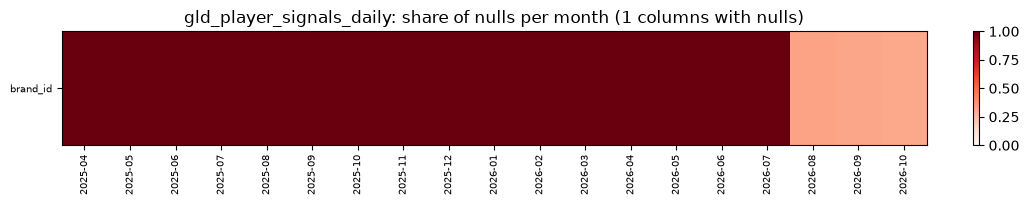

gld_player_engagement_daily: no nulls in any column
gld_player_financial_daily: no nulls in any column
gld_player_gaming_daily: no nulls in any column
gld_player_payments_daily: no nulls in any column


In [31]:
TABLES = ["gld_player_signals_daily", "gld_player_engagement_daily", "gld_player_financial_daily",
          "gld_player_gaming_daily", "gld_player_payments_daily"]
for table in TABLES:
    nulls = audit.footer_nulls(table)
    nulls.columns = pd.to_datetime(nulls.columns)
    monthly = nulls.T.resample("MS").mean().T
    monthly = monthly[monthly.max(axis=1) > 0]
    if monthly.empty:
        print(f"{table}: no nulls in any column")
        continue
    fig, ax = plt.subplots(figsize=(12, 0.28 * len(monthly) + 1.2))
    im = ax.imshow(monthly.to_numpy(), aspect="auto", cmap="Reds", vmin=0, vmax=1)
    ax.set_yticks(range(len(monthly)), monthly.index, fontsize=7)
    ax.set_xticks(range(len(monthly.columns)), [c.strftime("%Y-%m") for c in monthly.columns], rotation=90, fontsize=7)
    ax.set_title(f"{table}: share of nulls per month ({len(monthly)} columns with nulls)")
    fig.colorbar(im, ax=ax, fraction=0.02)
    plt.show()

Many columns write **0** instead of null when there is no value. The share of zeros is in the scorecard (section 3).

## 2. Impossible Values in the Whole History

Daily maximum of each column against its real-life limit, from the file metadata (no S3). It shows **if** and **when** there are impossible values; section 3 counts **how many**.

In [32]:
rows = []
for name, m in cfg["metrics"].items():
    if not m["expr"].isidentifier():
        continue
    try:
        r = audit.footer_range(m["table"], m["expr"])
    except (FileNotFoundError, KeyError):
        continue
    if r.empty:
        continue
    lo, hi = m["range"]
    bad = r[r["max_num"] > hi]
    rows.append({"metric": name, "column": m["expr"], "range top": hi, "days": len(r),
                 "days above the range": len(bad), "first": bad.index.min() if len(bad) else "",
                 "last": bad.index.max() if len(bad) else "", "highest value": r["max_num"].max()})
display(pd.DataFrame(rows))

,metric,column,range top,days,days above the range,first,last,highest value
0,turnover_player_day,turnover_eur,1000000,554,225,2025-04-02,2026-10-06,1.501590e+07
1,wagered_eur_l30d,wagered_eur_l30d,10000000,554,452,2025-05-13,2026-10-06,1.022890e+08
2,avg_bet_eur_l30d,avg_bet_eur_l30d,50000,554,0,,,3.755816e+04
3,sessions_per_active_day,sessions_today,100,554,0,,,3.400000e+01
4,active_days_l30d,active_days_l30d,30,554,0,,,3.000000e+01
5,bets_per_active_day,bets,100000,554,4,2026-08-20,2026-08-24,1.368790e+05
6,deposits_per_day,deposit_count,50,344,165,2026-02-23,2026-10-05,1.800000e+02
7,session_duration_avg_secs,tp_avg_session_duration_secs,14400,554,93,2026-07-06,2026-10-06,2.413975e+06
8,session_gap_avg_hours,tp_avg_session_gap_hours,2160,554,4,2026-08-08,2026-09-26,2.178620e+03
9,night_index,tp_night_index,1,554,93,2026-07-06,2026-10-06,4.000000e+00


## 3. Scorecard

One line per metric:

- **outside range %:** values outside the real-life range;
- **peaks:** peaks of the histogram (one is expected);
- **best fit** and **KS distance:** the closest curve and the largest gap to it. Below 0.03 is a **close** fit, below 0.08 **acceptable**, above that **different**. With millions of rows every test fails, so I use the distance.

In [33]:
profiles, results, card = {}, {}, []
for name in METRICS:
    prof, hist = audit.metric_data(cfg, name)
    res = stats.fit(cfg, name, prof, hist)
    profiles[name], results[name] = prof, res
    card.append(stats.summary_row(cfg, name, prof, res))
scorecard = pd.DataFrame(card).set_index("metric")
scorecard.style.format({"rows": "{:,}", "null %": "{:.1f}", "p1": "{:.3g}", "median": "{:.3g}", "p99": "{:.3g}",
                        "max": "{:.3g}", "outside range %": "{:.2f}", "KS distance": "{:.3f}"})

,table,expected,rows,null %,p1,median,p99,max,outside range %,peaks,best fit,KS distance,fit
metric,,,,,,,,,,,,,
turnover_player_day,gld_player_gaming_daily,lognormal,"541,143",0.0,0.0713,139,1.44e+04,5.78e+06,0.14,1,Log-normal,0.030,close
wagered_eur_l30d,gld_player_signals_daily,lognormal,"2,179,191",0.0,0.75,193,9.82e+04,5.47e+07,0.04,1,Log-normal,0.033,acceptable
avg_bet_eur_l30d,gld_player_signals_daily,lognormal,"2,179,191",0.0,0.0245,0.385,71.8,2.31e+04,0.14,1,Log-normal,0.071,acceptable
deposit_size_eur,gld_player_payments_daily,lognormal,"395,220",0.0,4.43,21.6,630,4.85e+05,0.05,1,Log-normal,0.063,acceptable
sessions_per_active_day,gld_player_engagement_daily,count,"546,907",0.0,1,1,9,22,0.00,1,Negative binomial,0.006,close
active_days_l30d,gld_player_signals_daily,count,"2,217,627",0.0,1,2,29,30,0.00,1,Negative binomial,0.071,acceptable
bets_per_active_day,gld_player_gaming_daily,count,"545,380",0.0,1,265,7.08e+03,3.83e+04,0.00,1,Log-normal,0.073,acceptable
deposits_per_day,gld_player_payments_daily,count,"398,831",0.0,1,1,13,180,0.01,1,Negative binomial,0.009,close
session_duration_avg_secs,gld_player_signals_daily,lognormal,"4,715,183",0.0,1,1.66e+03,5.89e+04,2.41e+06,8.39,1,Log-normal,0.073,acceptable


### Impossible values per variable

The real-life range of each metric and how many values fall outside it. In the plots below they are red.

In [34]:
impossible = pd.DataFrame({n: {"range": cfg["metrics"][n]["range"], "rows": int(p["n"]), "min": p["min"], "max": p["max"],
                               "below": int(p["below_range"]), "above": int(p["above_range"]),
                               "impossible %": 100 * (p["below_range"] + p["above_range"]) / p["n"]}
                           for n, p in profiles.items()}).T
impossible.sort_values("impossible %", ascending=False)

,range,rows,min,max,below,above,impossible %
hourly_entropy,"[0, 1]",8336837,0.0,4.562882,0,2134905,25.608093
weekend_index,"[0, 1]",8336837,0.0,3.5,0,1813194,21.749184
session_duration_avg_secs,"[10, 14400]",4715183,1.0,2413975.0,101046,294693,8.392866
night_index,"[0, 1]",8336837,0.0,4.0,0,651683,7.816909
median_session_duration_secs,"[10, 14400]",4715183,1.0,2413975.0,145267,164830,6.576563
session_gap_avg_hours,"[0.01, 2160]",2792061,-178.491501,2160.160156,26239,1,0.939808
turnover_player_day,"[0.01, 1000000]",541143,0.0001,5780959.0747,747,25,0.142661
avg_bet_eur_l30d,"[0.01, 50000]",2179191,0.0002,23130.1277,3046,0,0.139777
deposit_size_eur,"[1, 100000]",395220,0.0035,484869.0,198,9,0.052376
wagered_eur_l30d,"[0.01, 10000000]",2179191,0.0018,54697604.5981,841,48,0.040795


## 4. Money: Log-Normal

On a log scale, a log-normal metric is a bell with one peak. Dotted lines: real-life range. Dashed lines: peaks.

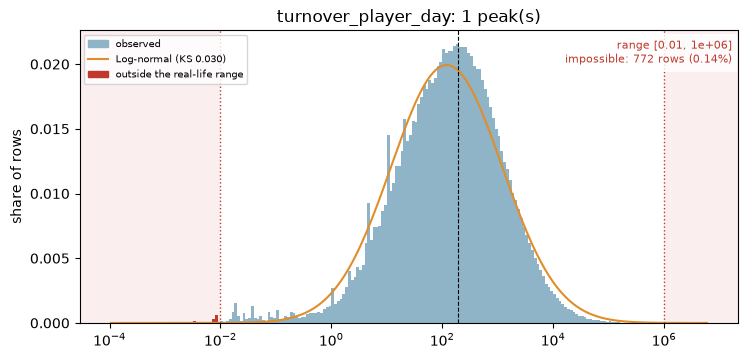

turnover_player_day: skewness of ln(x) -0.59 (0 for a log-normal), excess kurtosis of ln(x) 1.34 (0 for a log-normal), zeros excluded by the population


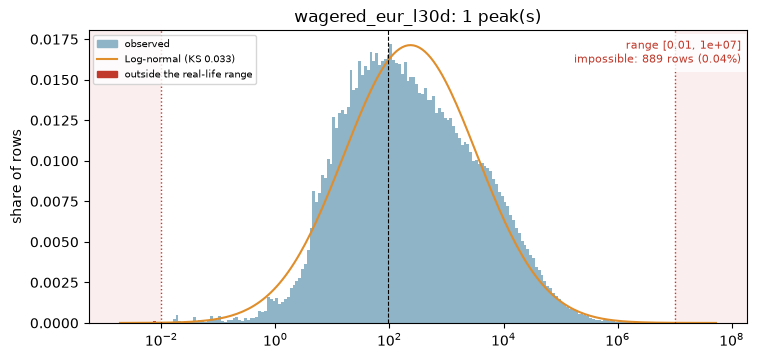

wagered_eur_l30d: skewness of ln(x) 0.11 (0 for a log-normal), excess kurtosis of ln(x) -0.16 (0 for a log-normal), zeros excluded by the population


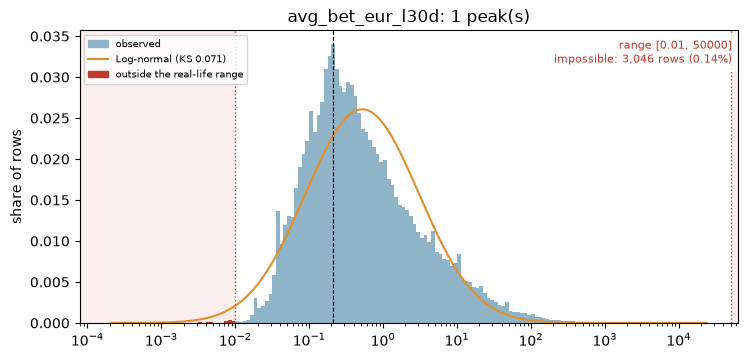

avg_bet_eur_l30d: skewness of ln(x) 0.74 (0 for a log-normal), excess kurtosis of ln(x) 0.51 (0 for a log-normal), zeros excluded by the population


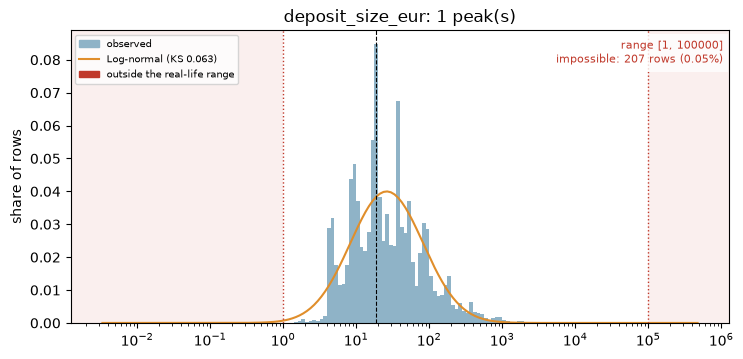

deposit_size_eur: skewness of ln(x) 0.60 (0 for a log-normal), excess kurtosis of ln(x) 0.70 (0 for a log-normal), zeros excluded by the population


In [35]:
money = [n for n, m in cfg["metrics"].items() if m["expected"] == "lognormal" and "session" not in n]
for name in money:
    plots.metric(cfg, results[name], profiles[name])
    plt.show()
    p = profiles[name]
    print(f"{name}: skewness of ln(x) {p['skew_ln']:.2f} (0 for a log-normal), "
          f"excess kurtosis of ln(x) {p['kurt_ln']:.2f} (0 for a log-normal), zeros excluded by the population")

## 5. Counts: Poisson

In a Poisson count, variance = mean. Here the variance is larger because each player has their own rate, so a **negative binomial** fits better. This is normal, not an error.

,mean,variance,dispersion index
sessions_per_active_day,2.12,3.05,1.44
active_days_l30d,5.19,42.81,8.25
bets_per_active_day,797.54,2159288.66,2707.44
deposits_per_day,2.38,6.96,2.92


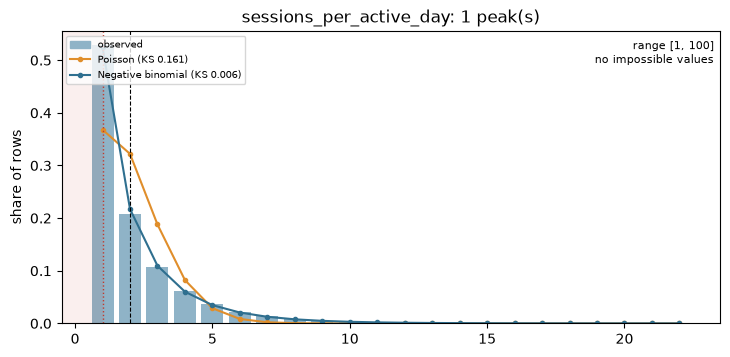

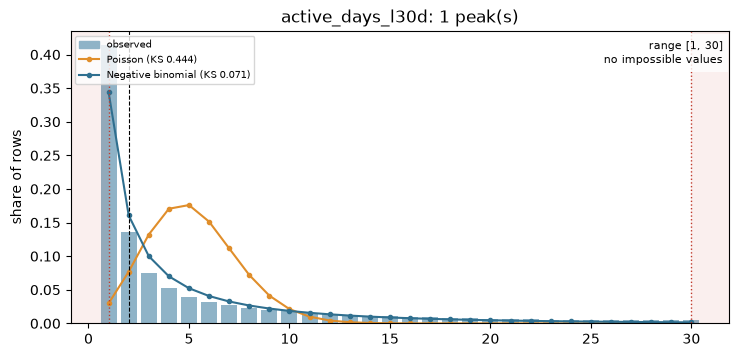

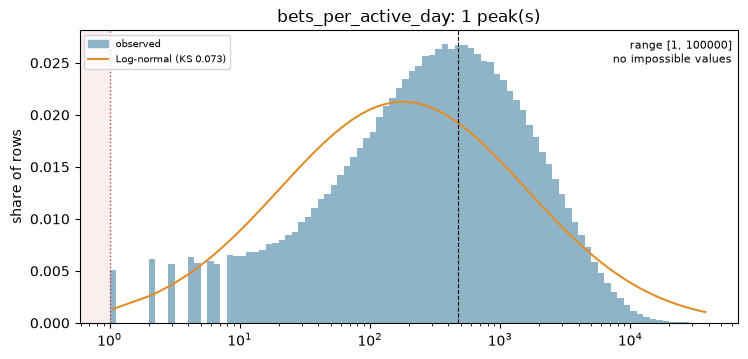

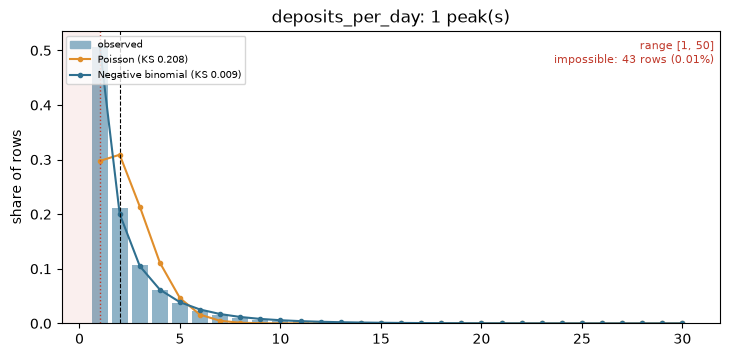

In [36]:
counts = [n for n, m in cfg["metrics"].items() if m["expected"] == "count"]
display(pd.DataFrame({n: {"mean": profiles[n]["mean"], "variance": profiles[n]["var"],
                          "dispersion index": profiles[n]["var"] / profiles[n]["mean"]} for n in counts}).T.round(2))
for name in counts:
    plots.metric(cfg, results[name], profiles[name])
    plt.show()

## 6. Durations and Delays

Sessions and gaps should be log-normal-like and inside human limits. The time to pay a withdrawal is compared with a **Gumbel** curve.

The processing delay cannot be measured here: each daily file is rewritten as one batch.

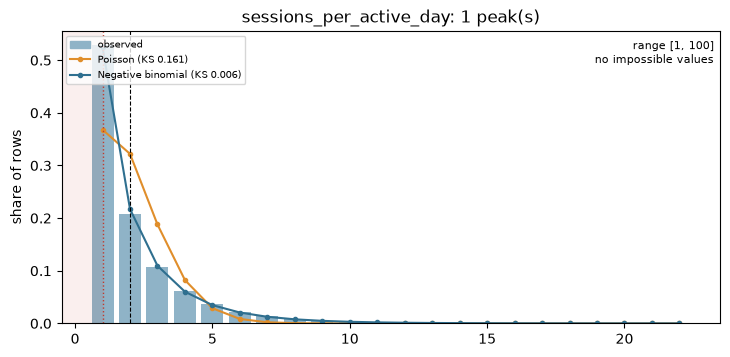

sessions_per_active_day: median 1, p99 9, max 22; 0.00% above 100


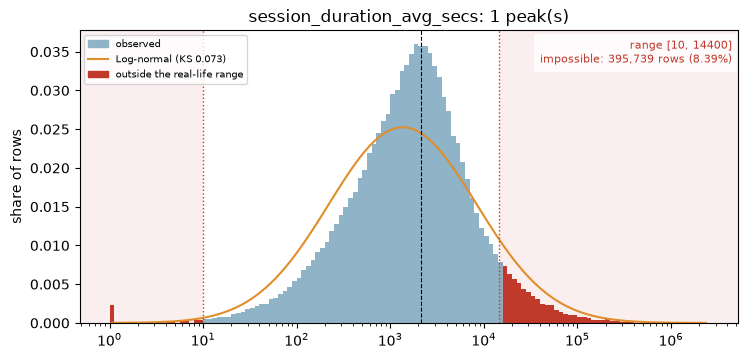

session_duration_avg_secs: median 1.66e+03, p99 5.89e+04, max 2.41e+06; 6.25% above 14400


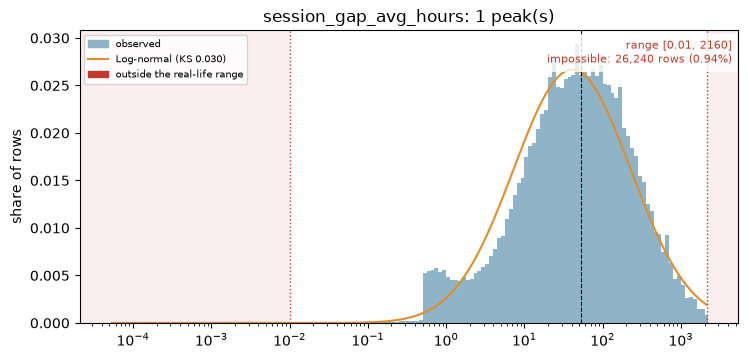

session_gap_avg_hours: median 45.4, p99 1.2e+03, max 2.16e+03; 0.00% above 2160


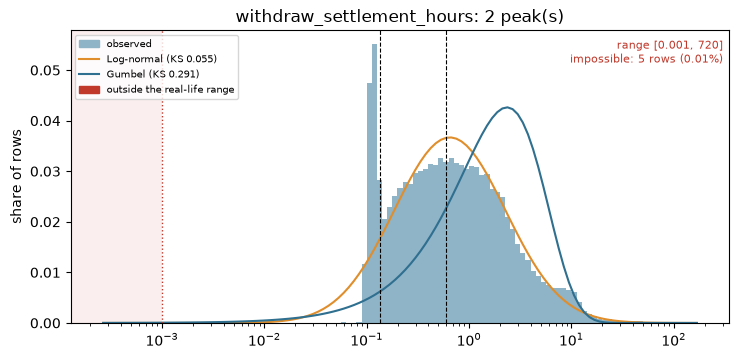

withdraw_settlement_hours: median 0.606, p99 13.1, max 165; 0.00% above 720


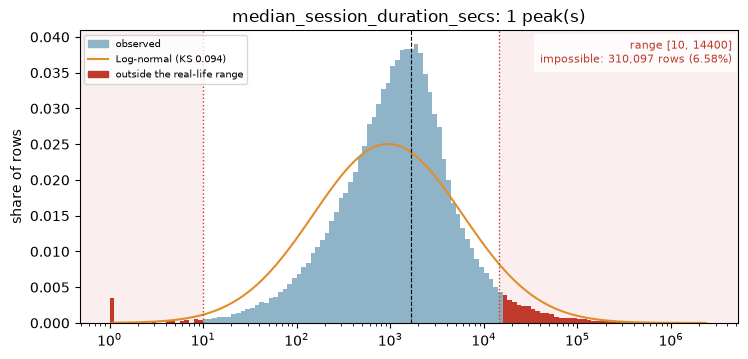

median_session_duration_secs: median 1.2e+03, p99 4.38e+04, max 2.41e+06; 3.50% above 14400


In [37]:
timing = [n for n, m in cfg["metrics"].items() if m["expected"] == "delay" or "session" in n]
for name in timing:
    plots.metric(cfg, results[name], profiles[name])
    plt.show()
    p = profiles[name]
    lo, hi = cfg["metrics"][name]["range"]
    print(f"{name}: median {p['quantiles'][4]:.3g}, p99 {p['quantiles'][7]:.3g}, max {p['max']:.3g}; "
          f"{100 * p['above_range'] / p['n']:.2f}% above {hi}")

## 7. Shares

A share must be between 0 and 1 (hold: at most 100%). Anything outside the dotted lines is an error.

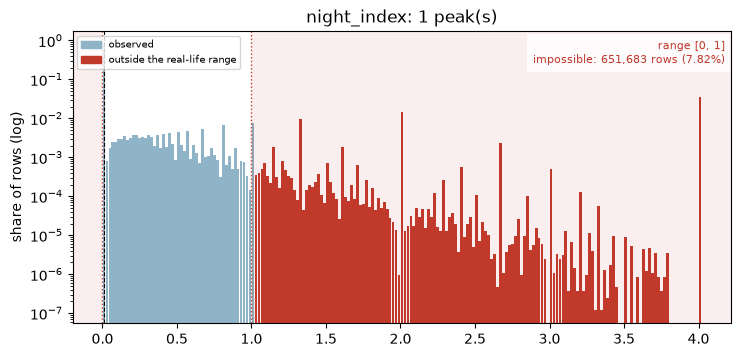

night_index: 0.00% below and 7.82% above the range


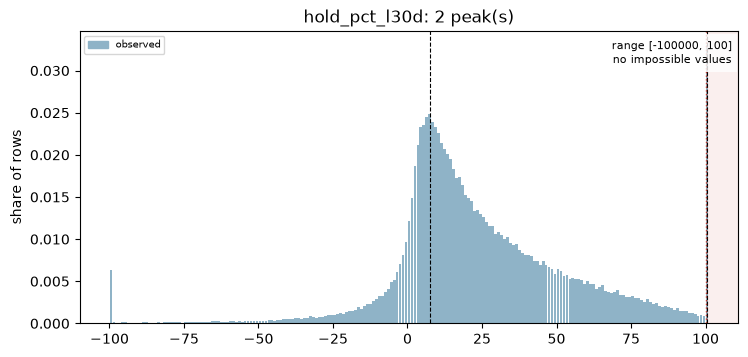

hold_pct_l30d: 0.00% below and 0.00% above the range


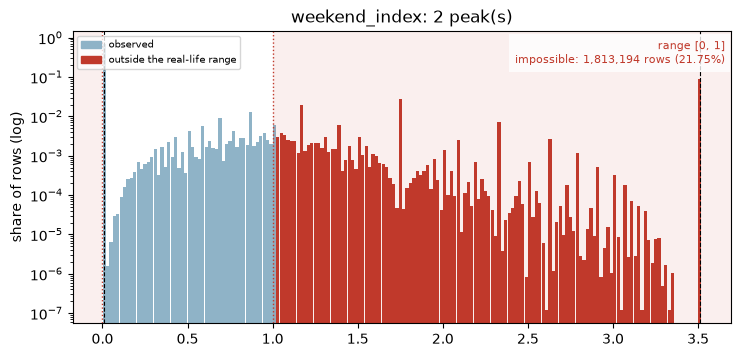

weekend_index: 0.00% below and 21.75% above the range


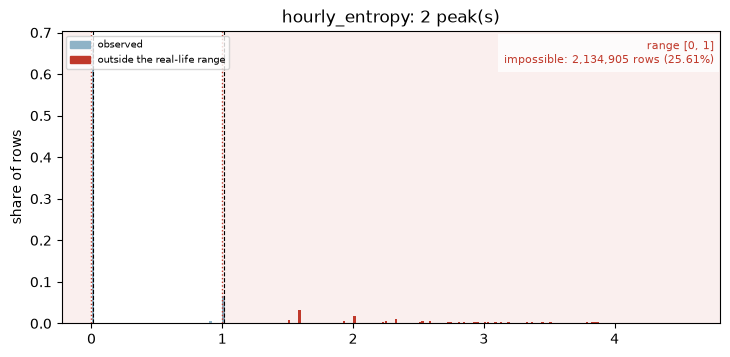

hourly_entropy: 0.00% below and 25.61% above the range


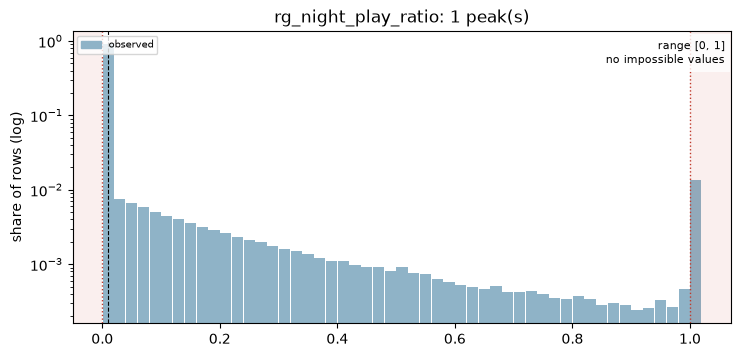

rg_night_play_ratio: 0.00% below and 0.00% above the range


In [38]:
for name in [n for n, m in cfg["metrics"].items() if m["expected"] == "share"]:
    plots.metric(cfg, results[name], profiles[name])
    plt.show()
    p = profiles[name]
    print(f"{name}: {100 * p['below_range'] / p['n']:.2f}% below and {100 * p['above_range'] / p['n']:.2f}% above the range")

## 8. Point Masses

A **point mass** is one exact value that is much more common than its neighbours. It usually means a default value or a rule of the computation.

In [39]:
for name in [n for n, m in cfg["metrics"].items() if m["scale"] == "int" or m.get("integer")]:
    print(name)
    display(stats.point_masses(cfg, name, audit.metric_data(cfg, name)[1]).round(3))

sessions_per_active_day


,value,share %,exact value
0,1,52.944,True
1,2,20.738,True
2,3,10.795,True
3,4,6.244,True
4,5,3.711,True
5,10,0.285,True


active_days_l30d


,value,share %,exact value
0,1,41.461,True
1,2,13.650,True
2,3,7.479,True
3,4,5.310,True
4,5,3.979,True
5,10,1.788,True


bets_per_active_day


...

,value,share %,exact value
0,1,50.587,True
1,2,21.202,True
2,3,10.734,True
3,4,6.109,True
4,5,3.658,True
5,10,0.500,True


session_duration_avg_secs


,value,share %,exact value
0,1,1.836,True
1,2,0.029,True
2,3,0.040,True
3,4,0.049,True
4,5,0.035,True
5,10,0.083,False


median_session_duration_secs


,value,share %,exact value
0,1,2.743,True
1,2,0.036,True
2,3,0.042,True
3,4,0.050,True
4,5,0.039,True
5,10,0.093,False


## 9. Two Peaks: Which Groups Are Mixed?

For each metric with two peaks, I split it by brand, currency and other segments. If each group has one peak, the two peaks come from mixing the groups.

metrics with more than one peak: ['withdraw_settlement_hours', 'hold_pct_l30d', 'weekend_index', 'hourly_entropy']


,segment,rows,peaks,peak positions,split_by
0,23,30569,1,0.531,brand_id
1,73,27508,2,"0.119, 0.668",brand_id
2,64,10319,1,0.237,brand_id
3,72,9235,1,0.119,brand_id
4,14,7926,2,"1.5, 9.44",brand_id


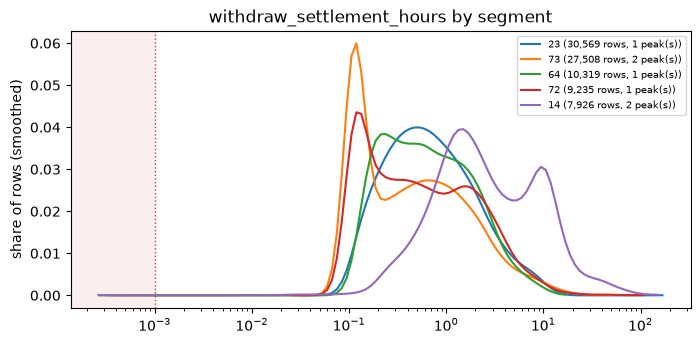

,segment,rows,peaks,peak positions,split_by
0,TRY,69218,1,0.596,currency
1,EUR,15427,1,0.119,currency
2,PLN,758,2,"0.119, 0.596",currency
3,INR,137,2,"1.88, 11.9",currency
4,USDT,12,4,"0.15, 0.473, 1.19, 15",currency
5,,5,1,0.119,currency


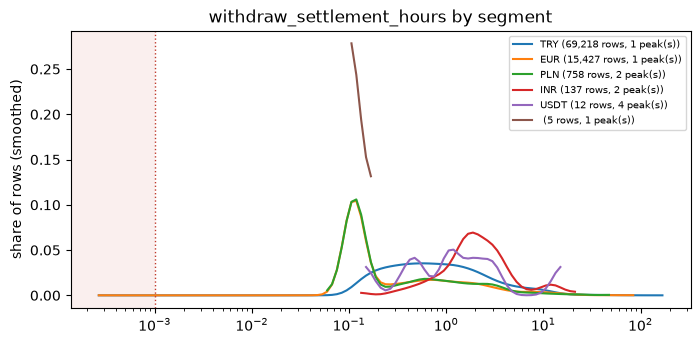

,segment,rows,peaks,peak positions,split_by
0,73,691153,2,"7.5, 100",brand_id
1,72,558349,2,"7.5, 100",brand_id
2,23,385413,2,"6.5, 100",brand_id
3,64,305245,2,"8.5, 100",brand_id
4,14,239031,2,"7.5, 100",brand_id


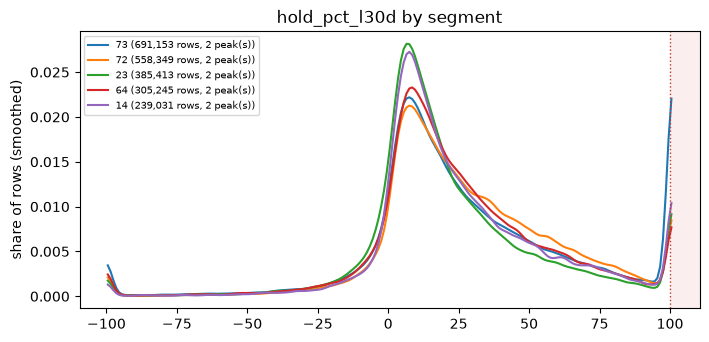

,segment,rows,peaks,peak positions,split_by
0,73,2678630,2,"0.01, 3.51",brand_id
1,72,2053233,2,"0.01, 3.51",brand_id
2,14,1332028,2,"0.01, 3.51",brand_id
3,23,1274979,2,"0.01, 3.51",brand_id
4,64,997967,2,"0.01, 3.51",brand_id


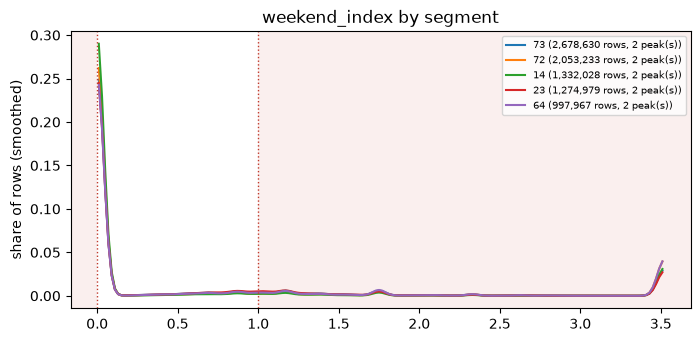

,segment,rows,peaks,peak positions,split_by
0,73,2678630,3,"0.01, 1.01, 1.59",brand_id
1,72,2053233,3,"0.01, 1.01, 1.59",brand_id
2,14,1332028,2,"0.01, 1.01",brand_id
3,23,1274979,2,"0.01, 1.01",brand_id
4,64,997967,3,"0.01, 1.01, 1.59",brand_id


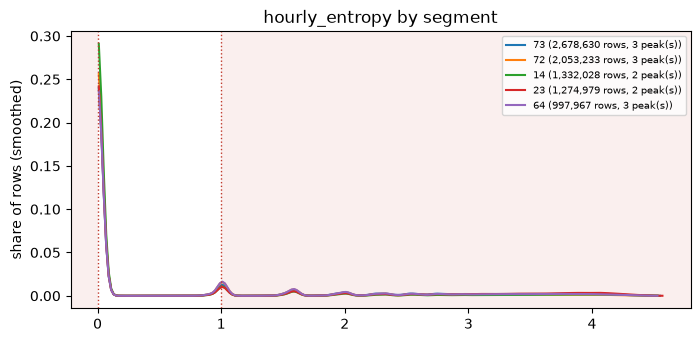

In [40]:
double = [n for n in METRICS if len(results[n]["peaks"]) > 1]
print("metrics with more than one peak:", double or "none")
for name in double:
    for segment in cfg["metrics"][name].get("segments", []):
        seg = audit.segment_histograms(cfg, name, segment)
        display(stats.segment_peaks(cfg, name, seg).head(cfg["thresholds"]["max_segments"]).assign(split_by=segment))
        plots.segments(cfg, name, seg)
        plt.show()

## 10. Impossible Values by Segment

For metrics with more than 0.5% of impossible values: where they are concentrated.

In [41]:
for name in METRICS:
    p = profiles[name]
    if (p["below_range"] + p["above_range"]) / p["n"] < 0.005:
        continue
    for segment in cfg["metrics"][name].get("segments", []):
        seg = audit.segment_histograms(cfg, name, segment)
        print(f"{name} by {segment}")
        display(stats.outside_by_segment(cfg, name, seg).round(2))

session_duration_avg_secs by brand_id


,segment,rows,below range %,above range %
0,73,1520942,1.00,11.96
1,72,1236441,4.34,2.00
2,23,685677,1.12,4.60
3,64,641271,2.93,1.54
4,14,630852,0.91,2.66


session_duration_avg_secs by lifecycle_stage


,segment,rows,below range %,above range %
0,Dormant,1856690,2.69,5.61
1,Active,1246680,0.61,5.85
2,New,988321,1.11,3.76
3,Churned,593765,5.40,7.44
4,Registered,21956,0.41,27.33
5,Reactivated,7771,5.67,4.38


session_gap_avg_hours by brand_id


...

,segment,rows,below range %,above range %
0,73,1520942,1.10,7.31
1,72,1236441,7.07,0.80
2,23,685677,1.18,2.09
3,64,641271,4.23,0.61
4,14,630852,0.94,1.50


weekend_index by brand_id


,segment,rows,below range %,above range %
0,73,2678630,0.0,22.21
1,72,2053233,0.0,22.19
2,14,1332028,0.0,16.28
3,23,1274979,0.0,22.15
4,64,997967,0.0,24.91


hourly_entropy by brand_id


,segment,rows,below range %,above range %
0,73,2678630,0.0,29.06
1,72,2053233,0.0,23.03
2,14,1332028,0.0,16.74
3,23,1274979,0.0,29.90
4,64,997967,0.0,28.01


## 11. Every Metric, Brand by Brand

The scorecard of section 3, one line per metric and brand. A metric can look fine for all brands together but not for one brand.

In [42]:
card = stats.brand_scorecard(cfg, METRICS)
cols = ["metric", "brand", "rows", "median", "p99", "max", "outside range %", "peaks", "peak positions", "best fit", "KS distance", "fit"]
display(card[cols].round(3))

,metric,brand,rows,median,p99,max,outside range %,peaks,peak positions,best fit,KS distance,fit
0,turnover_player_day,14,51515,190.382,26224.106,5780959.075,0.087,1,237,Log-normal,0.028,close
1,turnover_player_day,23,190194,171.493,15662.925,4597721.874,0.203,1,266,Log-normal,0.043,acceptable
2,turnover_player_day,64,72093,130.968,10759.078,857720.761,0.173,1,188,Log-normal,0.044,acceptable
3,turnover_player_day,72,71678,105.134,9596.235,447331.193,0.113,1,150,Log-normal,0.023,close
4,turnover_player_day,73,155663,116.195,13122.937,2454853.700,0.086,1,119,Log-normal,0.021,close
...,...,...,...,...,...,...,...,...,...,...,...,...
80,rg_night_play_ratio,14,1332028,0.000,1.000,1.000,0.000,1,0.01,,NaN,
81,rg_night_play_ratio,23,1274979,0.000,1.000,1.000,0.000,1,0.01,,NaN,
82,rg_night_play_ratio,64,997967,0.000,1.000,1.000,0.000,1,0.01,,NaN,
83,rg_night_play_ratio,72,2053233,0.000,1.000,1.000,0.000,1,0.01,,NaN,


**Where the brands differ:** how much the median changes between brands, which brand has the most values outside the range, and which brands have a different fit or number of peaks.

In [43]:
rows = []
for name, g in card.groupby("metric", sort=False):
    pos = g[g["median"] > 0]["median"]
    rows.append({"metric": name,
                 "median: largest / smallest brand": pos.max() / pos.min() if len(pos) > 1 else None,
                 "most outside range": f"{g.loc[g['outside range %'].idxmax(), 'brand']} ({g['outside range %'].max():.2f}%)",
                 "peaks per brand": ", ".join(f"{b}: {p}" for b, p in zip(g["brand"], g["peaks"])),
                 "fit per brand": ", ".join(f"{b}: {f or '-'}" for b, f in zip(g["brand"], g["fit"]))})
display(pd.DataFrame(rows).round(2))

,metric,median: largest / smallest brand,most outside range,peaks per brand,fit per brand
0,turnover_player_day,1.81,23 (0.20%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: close, 23: acceptable, 64: acceptable, 72: close, 73: close"
1,wagered_eur_l30d,5.76,14 (0.05%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: acceptable, 23: close, 64: close, 72: acceptable, 73: close"
2,avg_bet_eur_l30d,2.68,14 (0.23%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: acceptable, 23: acceptable, 64: acceptable, 72: acceptable, 73: acceptable"
3,deposit_size_eur,1.87,72 (0.09%),"14: 2, 23: 2, 64: 1, 72: 1, 73: 1","14: acceptable, 23: acceptable, 64: acceptable, 72: acceptable, 73: acceptable"
4,sessions_per_active_day,2.00,14 (0.00%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: close, 23: close, 64: close, 72: close, 73: close"
5,active_days_l30d,4.00,14 (0.00%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: different, 23: acceptable, 64: acceptable, 72: different, 73: acceptable"
6,bets_per_active_day,2.36,14 (0.00%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: acceptable, 23: acceptable, 64: acceptable, 72: acceptable, 73: different"
7,deposits_per_day,2.00,73 (0.03%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: close, 23: close, 64: close, 72: close, 73: close"
8,session_duration_avg_secs,1.88,73 (14.13%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: acceptable, 23: acceptable, 64: different, 72: different, 73: acceptable"
9,session_gap_avg_hours,1.54,73 (1.23%),"14: 1, 23: 1, 64: 1, 72: 1, 73: 1","14: close, 23: acceptable, 64: acceptable, 72: acceptable, 73: close"


**Distributions per brand:** one panel per brand, as in sections 4 to 7.

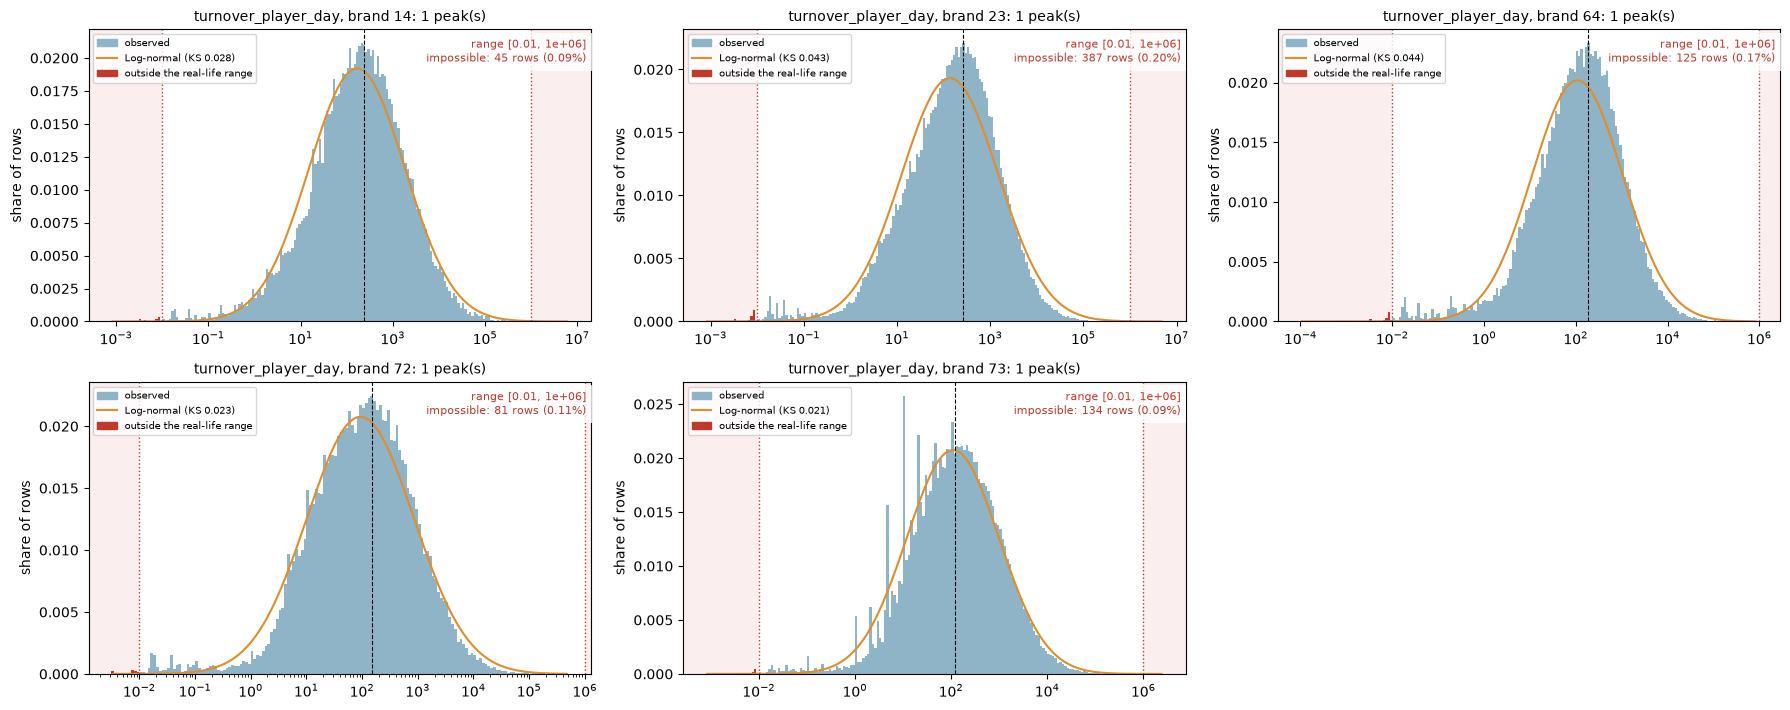

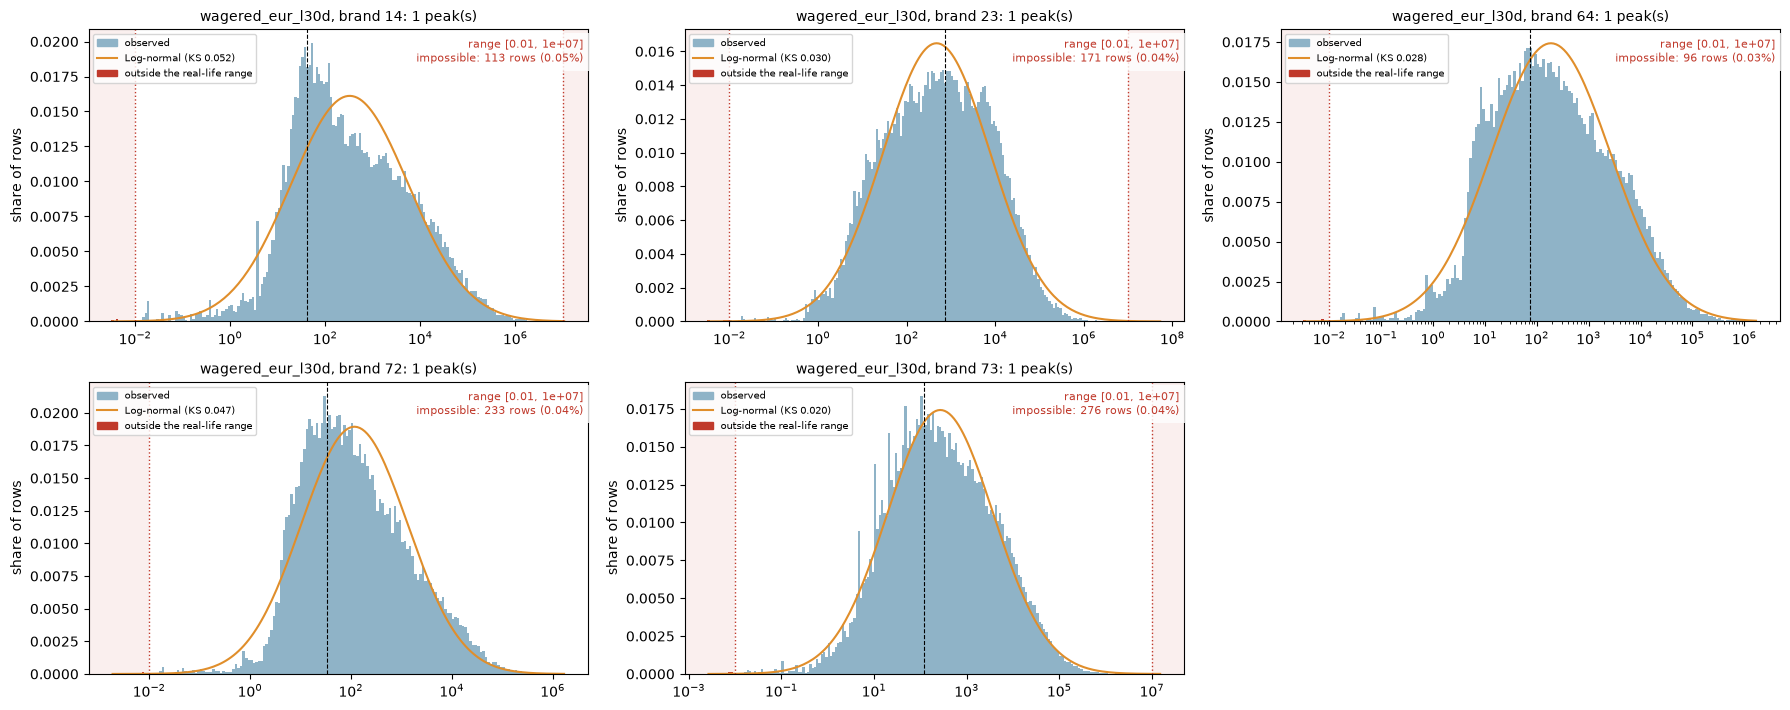

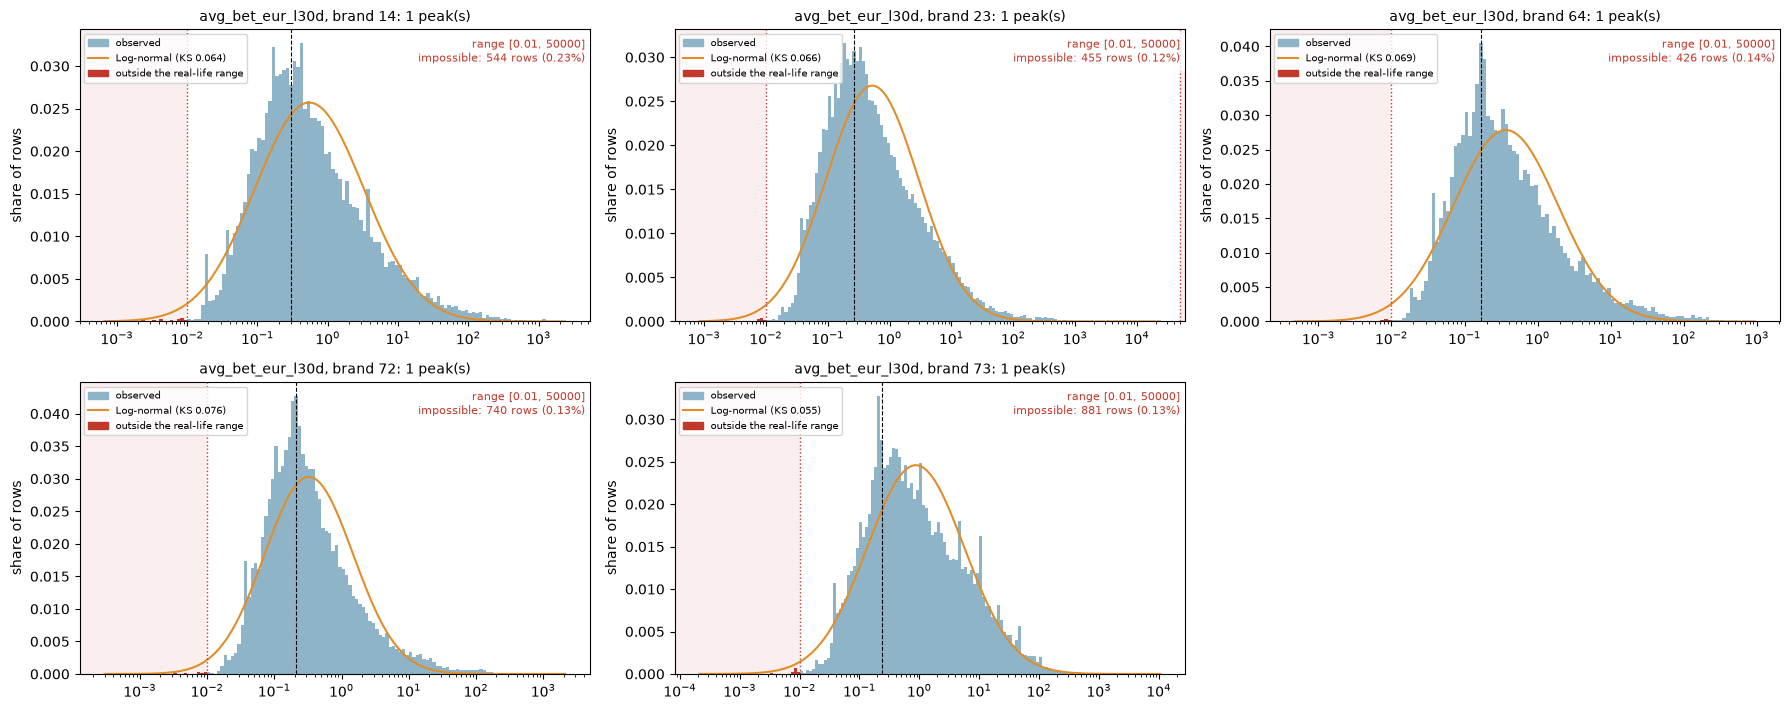

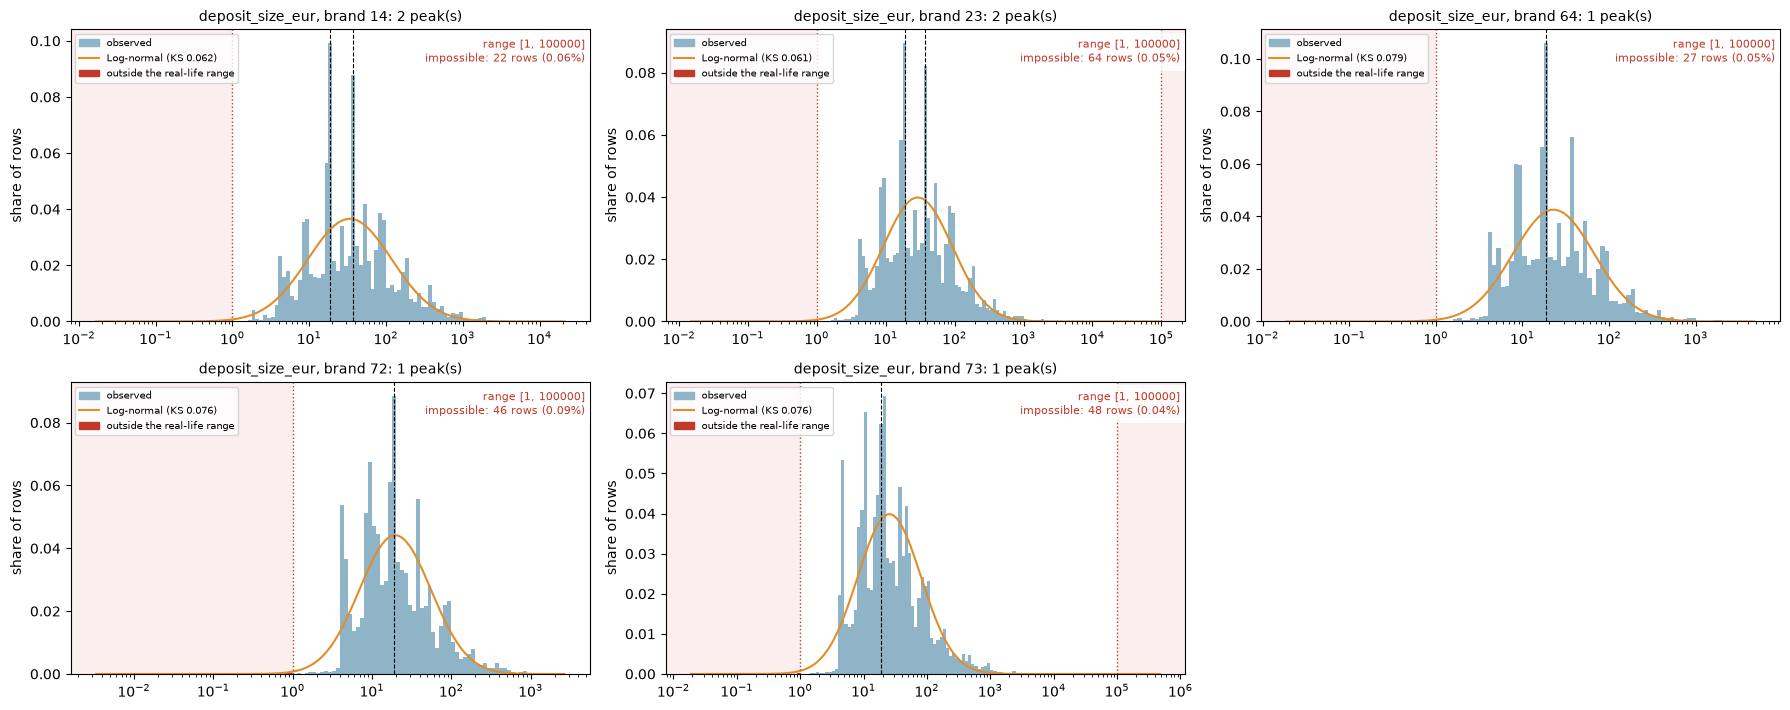

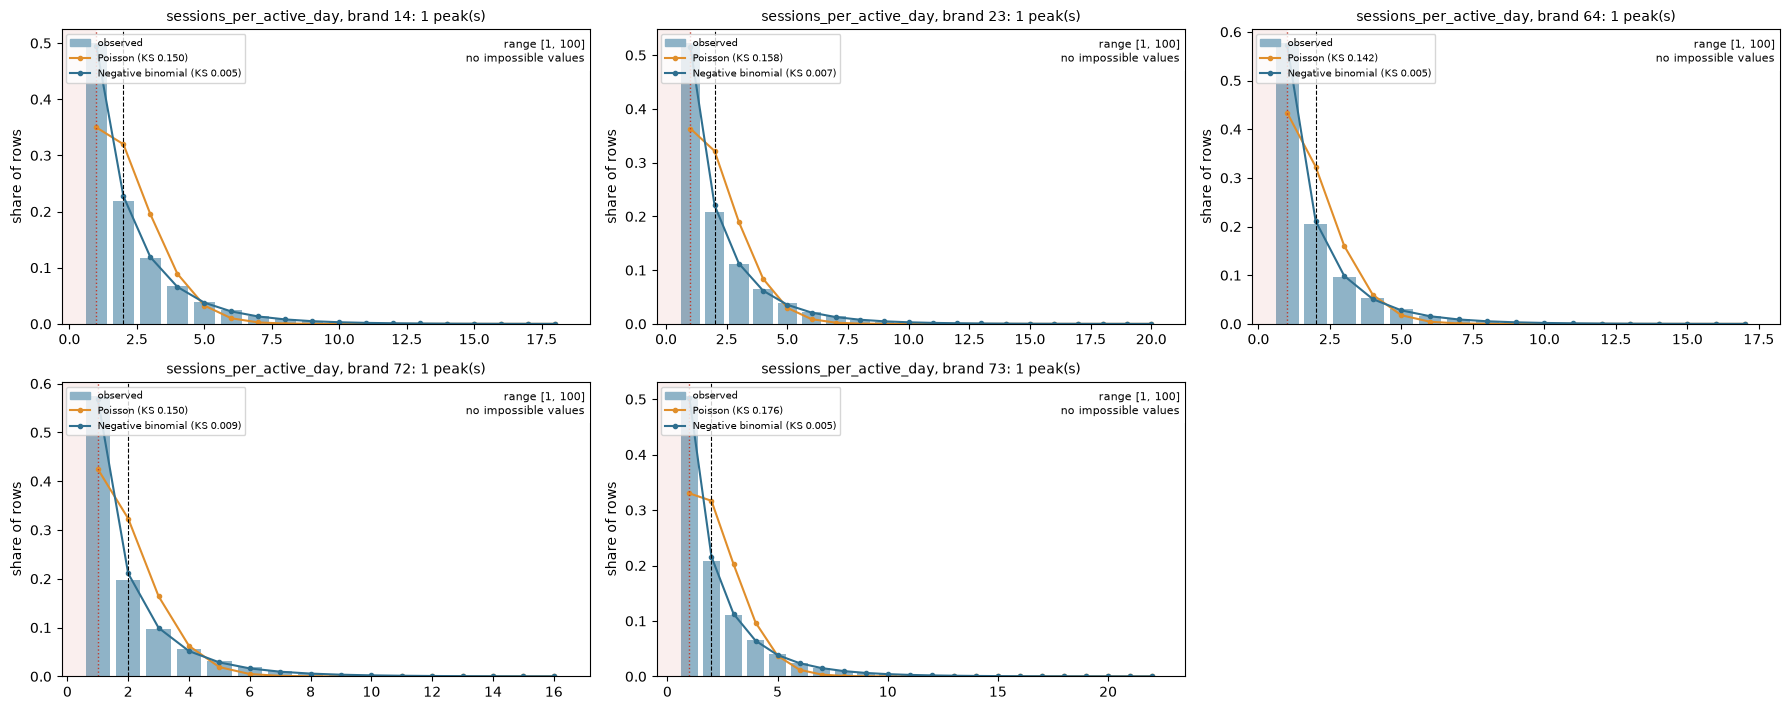

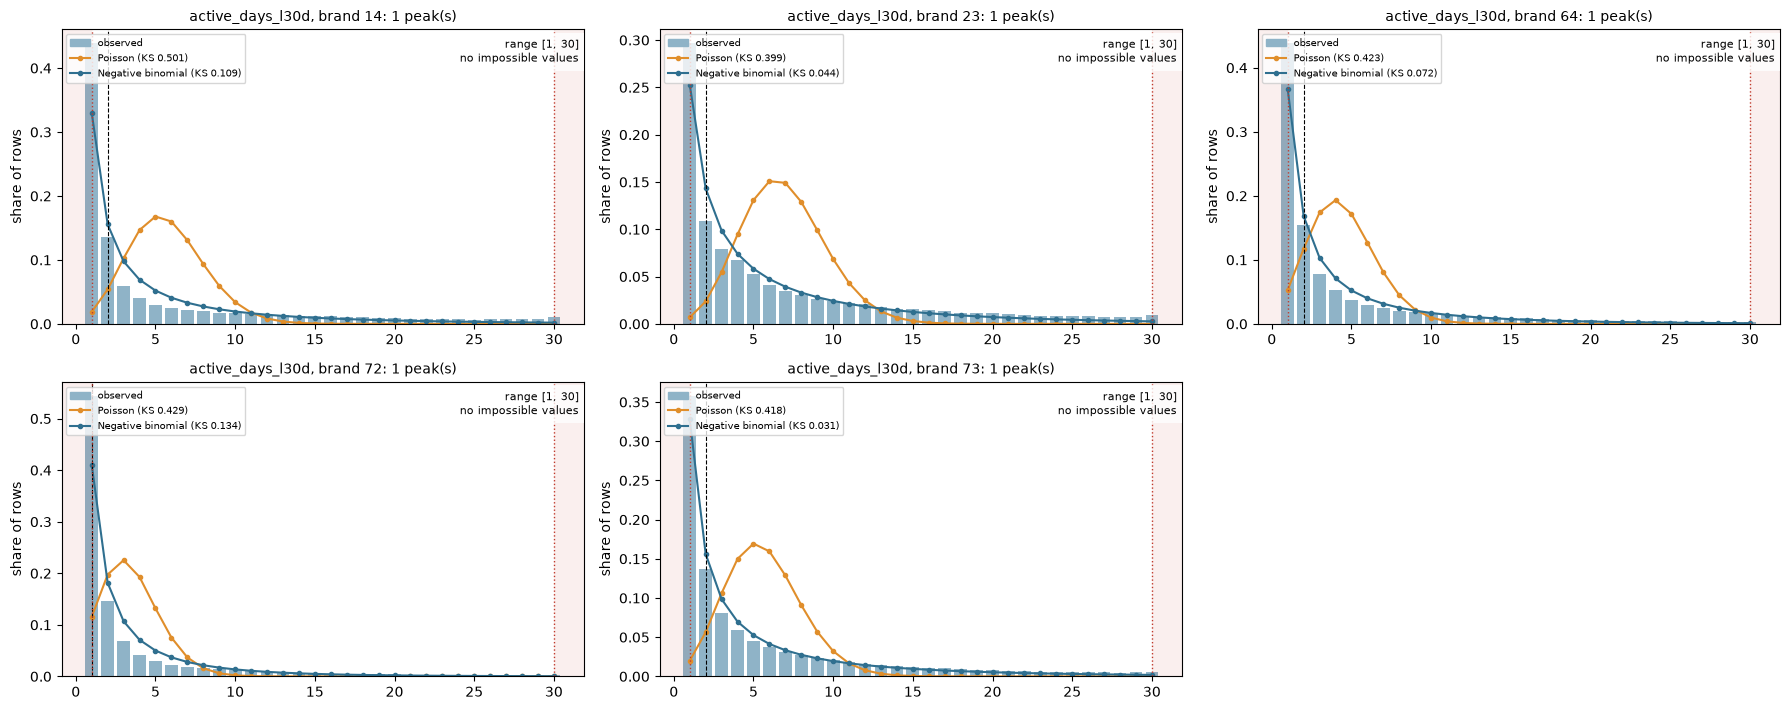

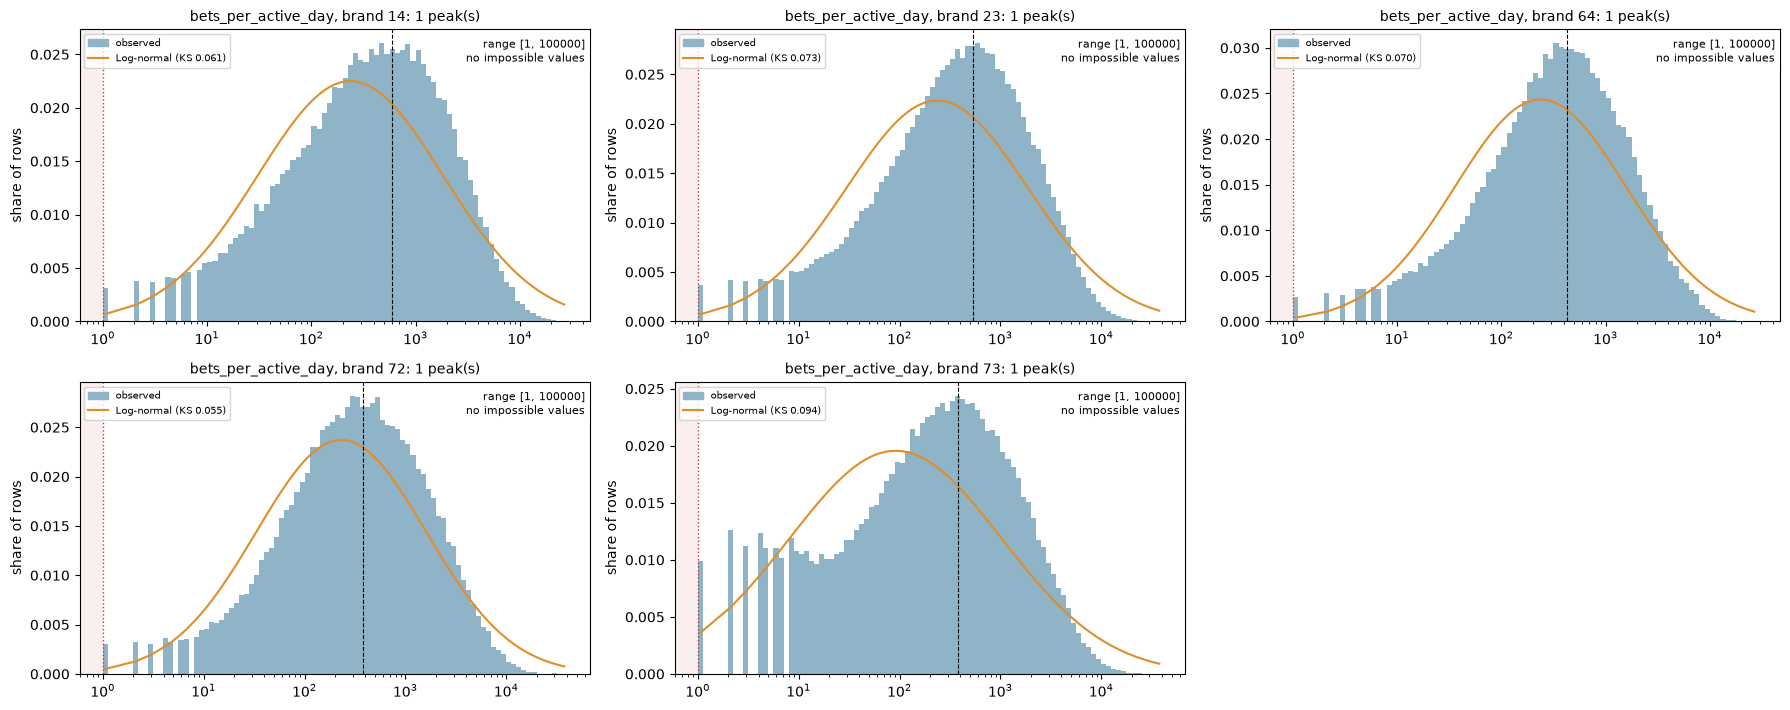

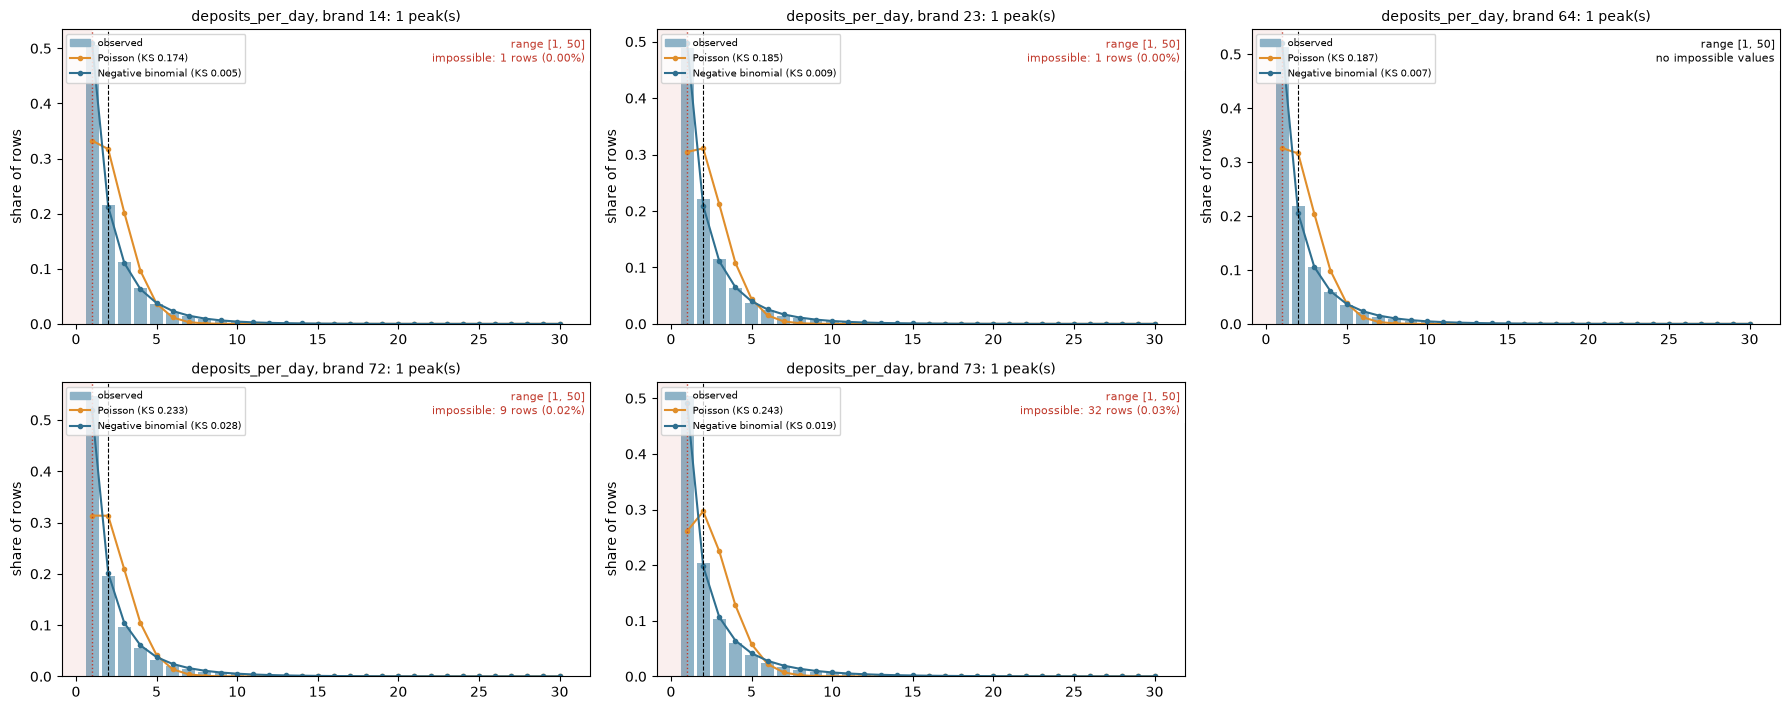

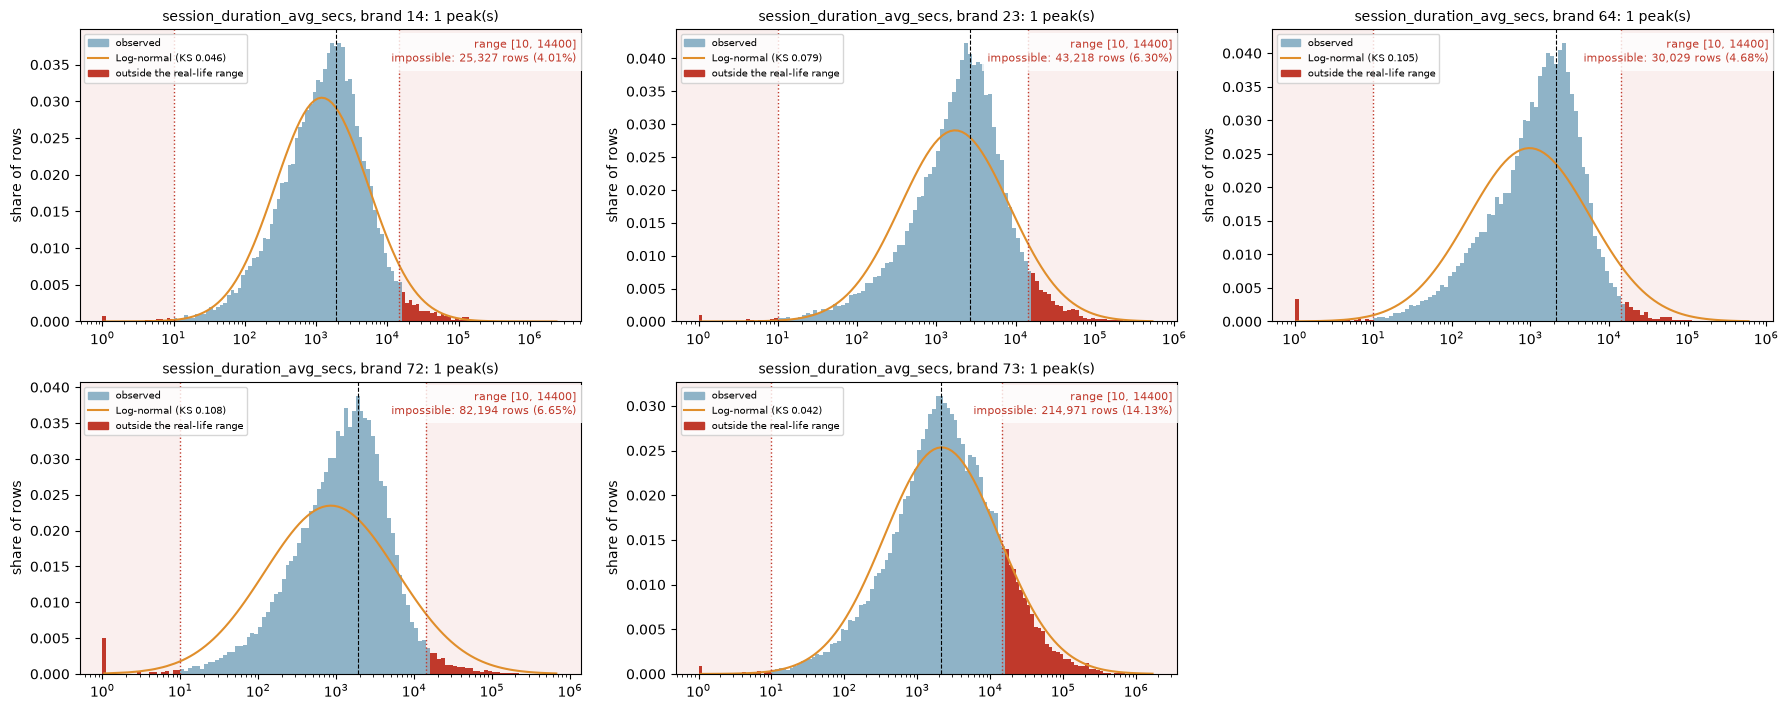

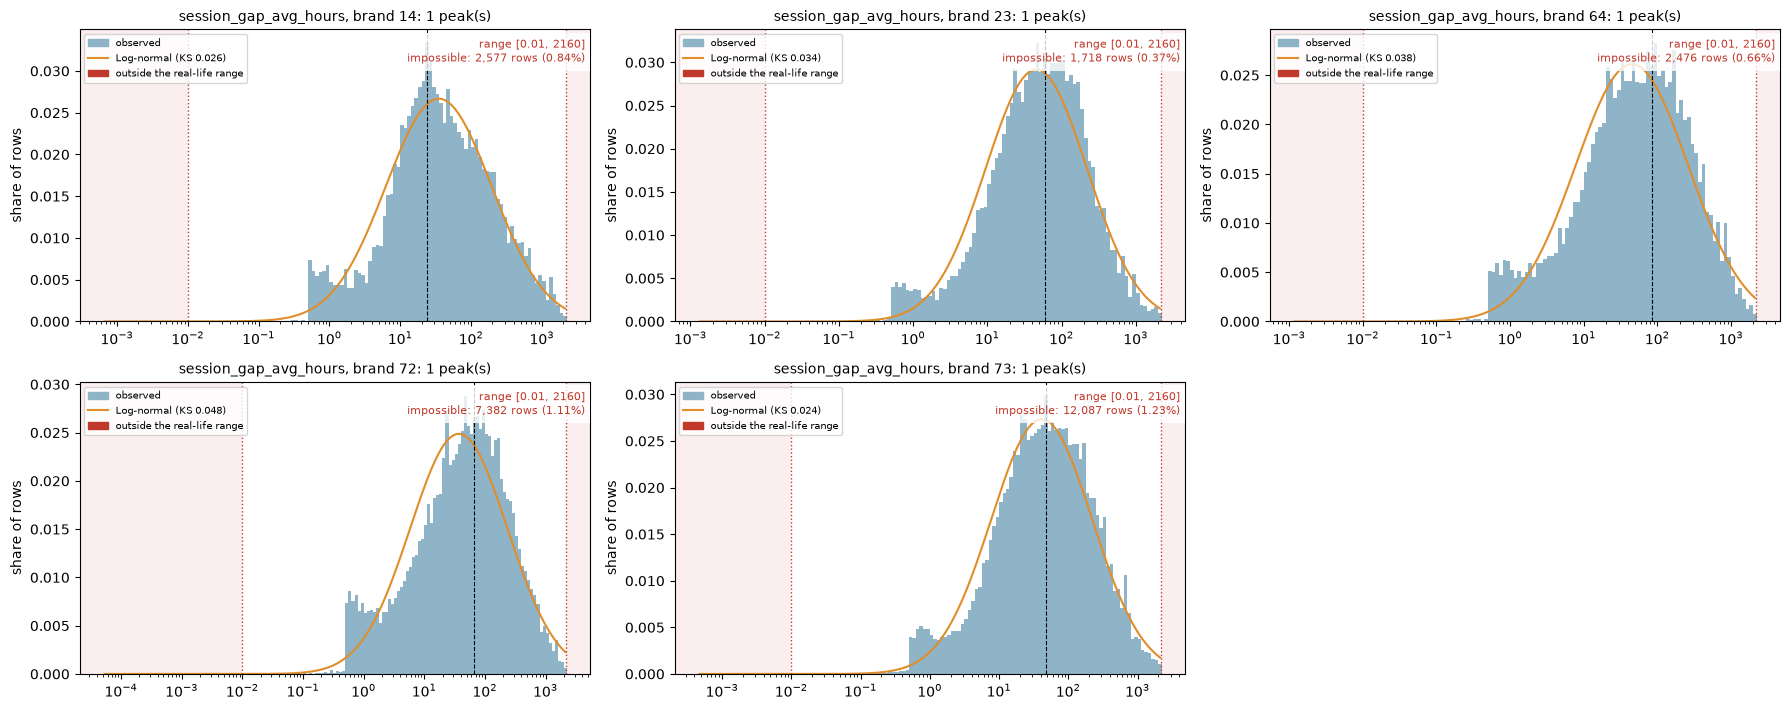

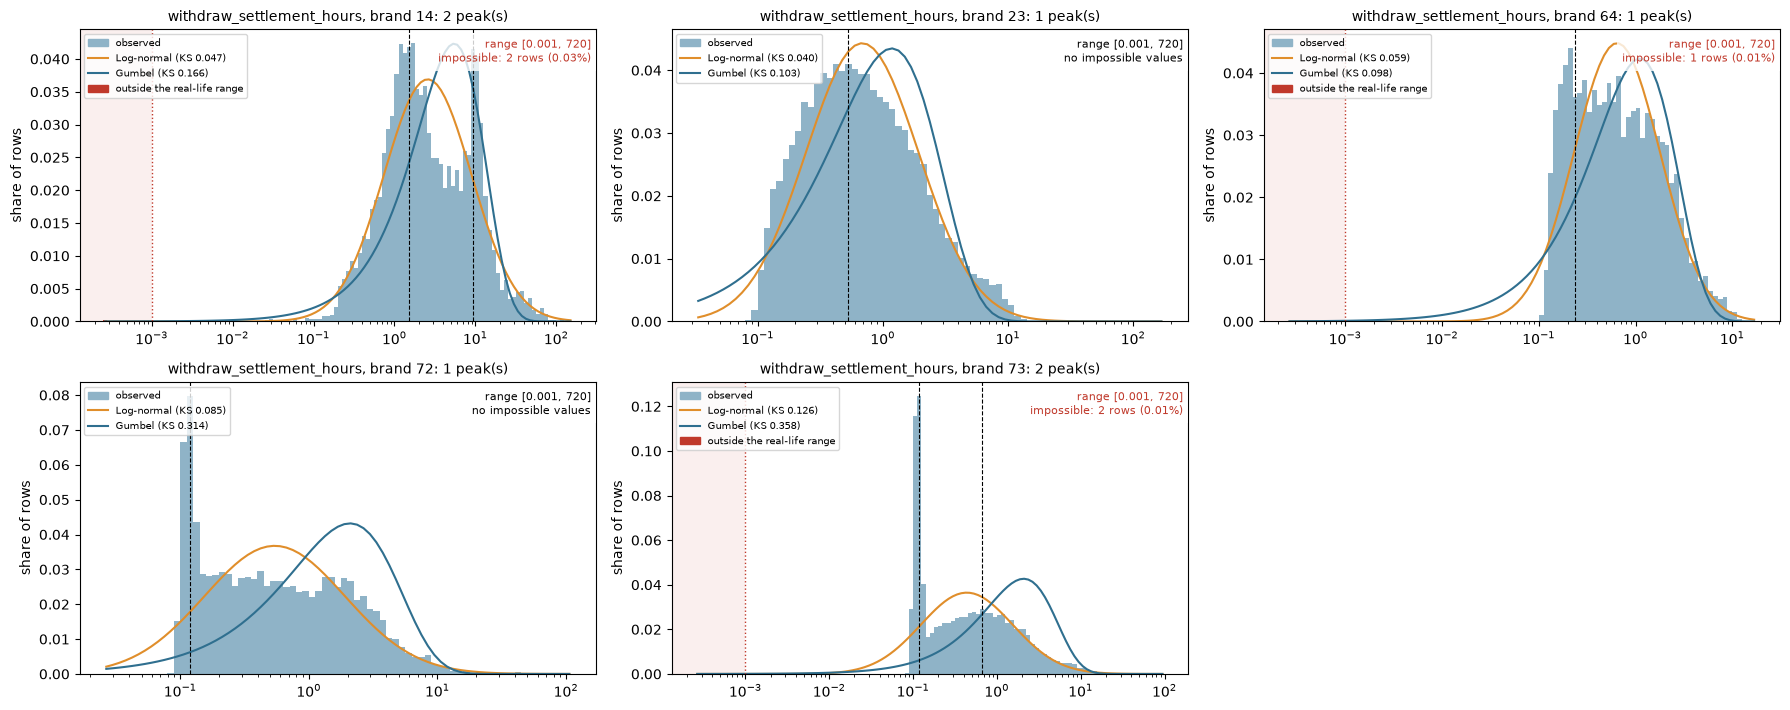

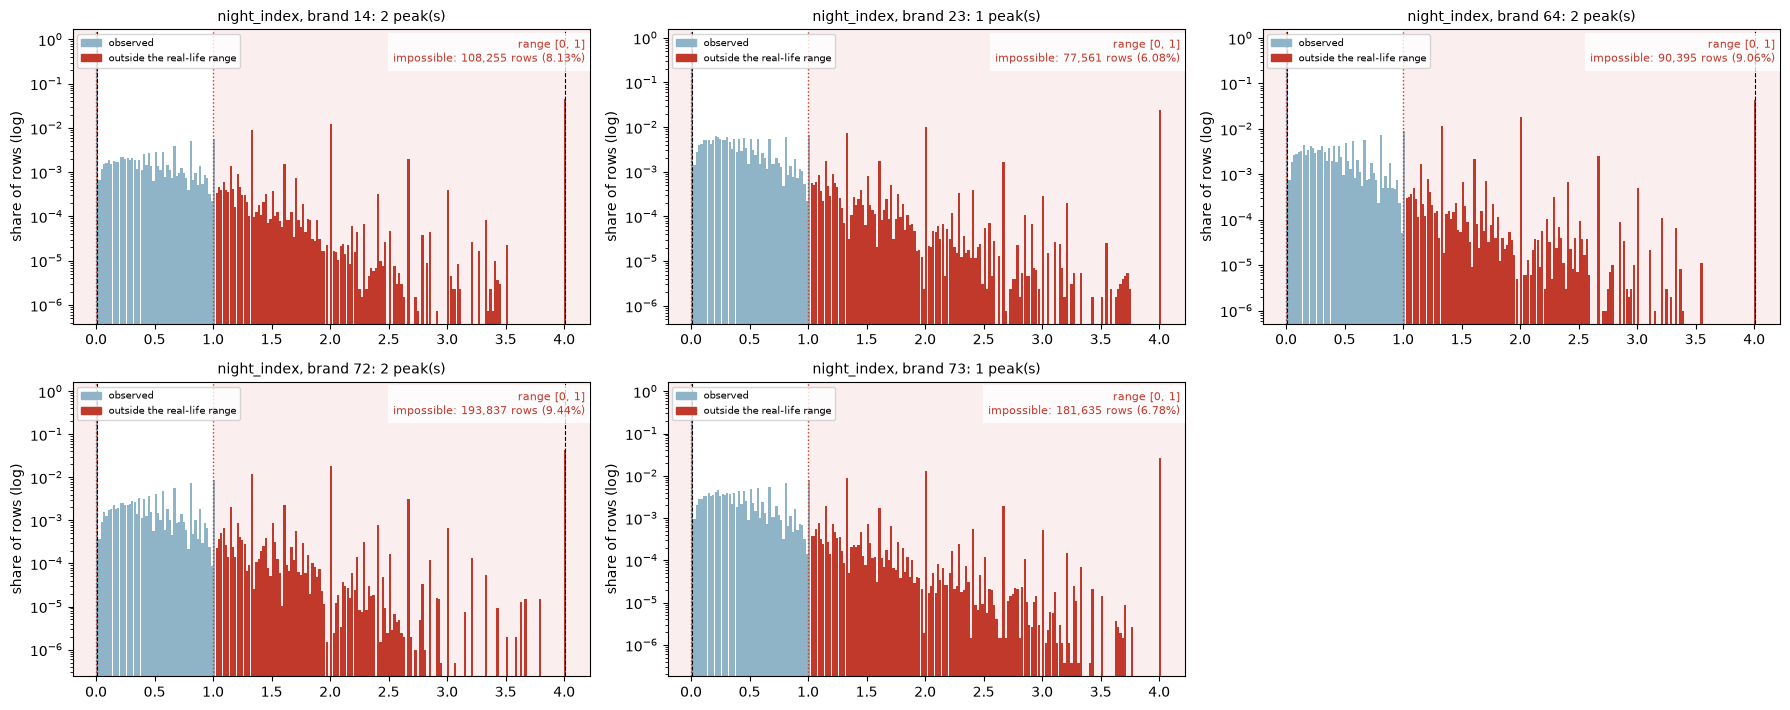

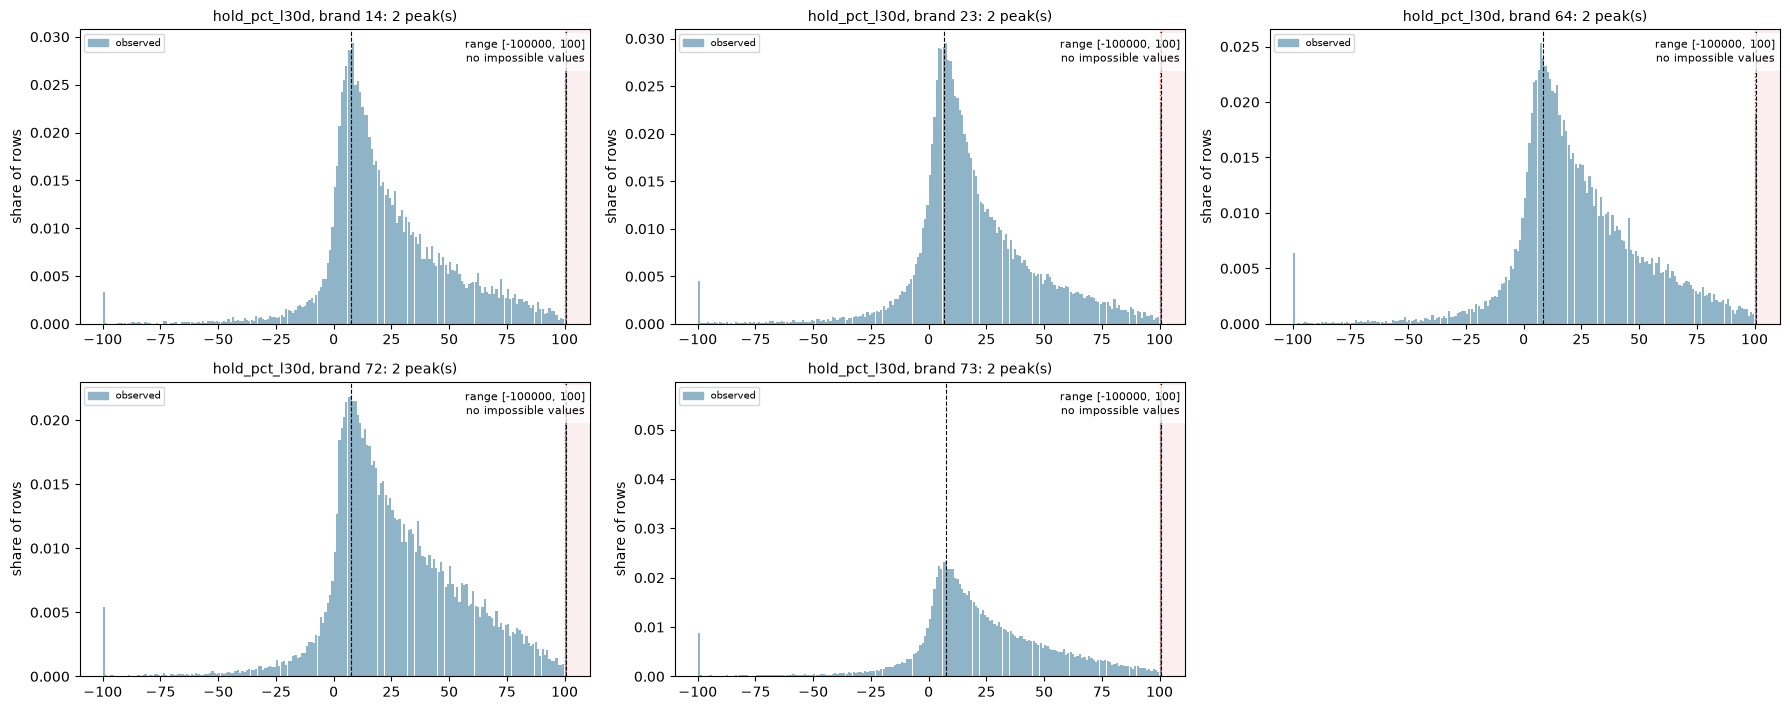

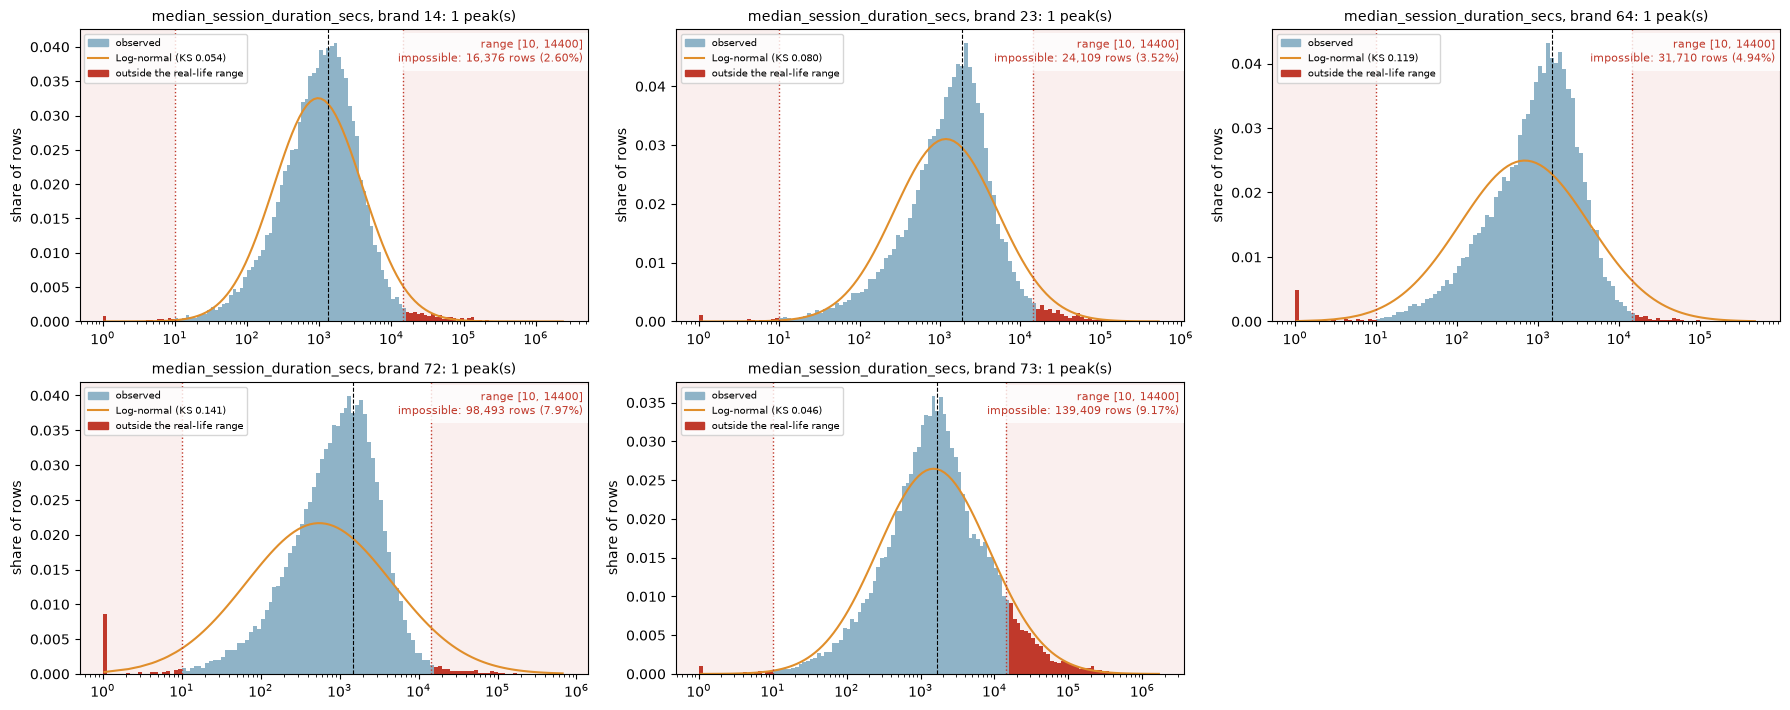

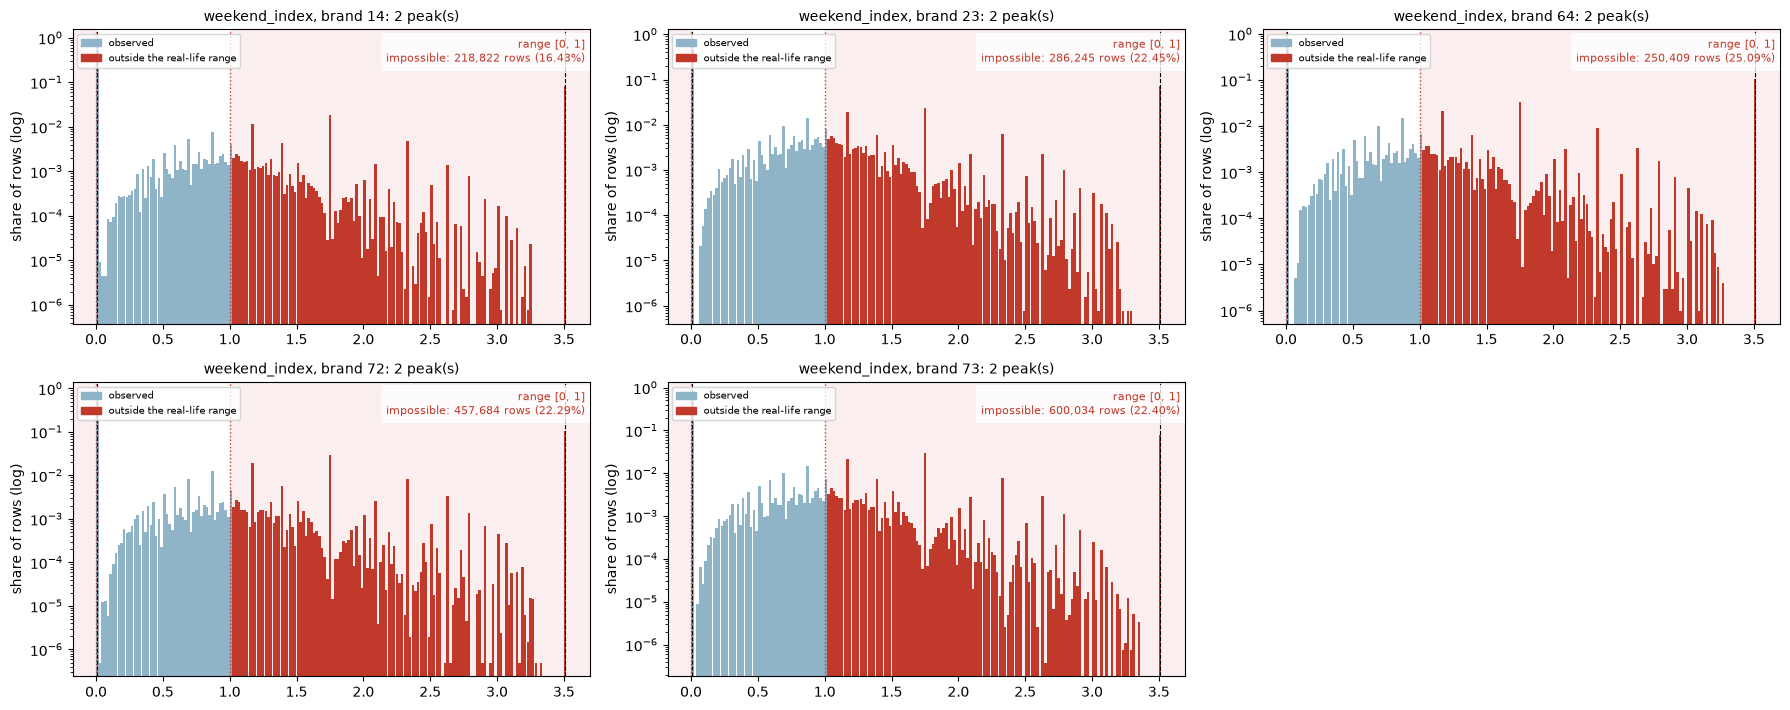

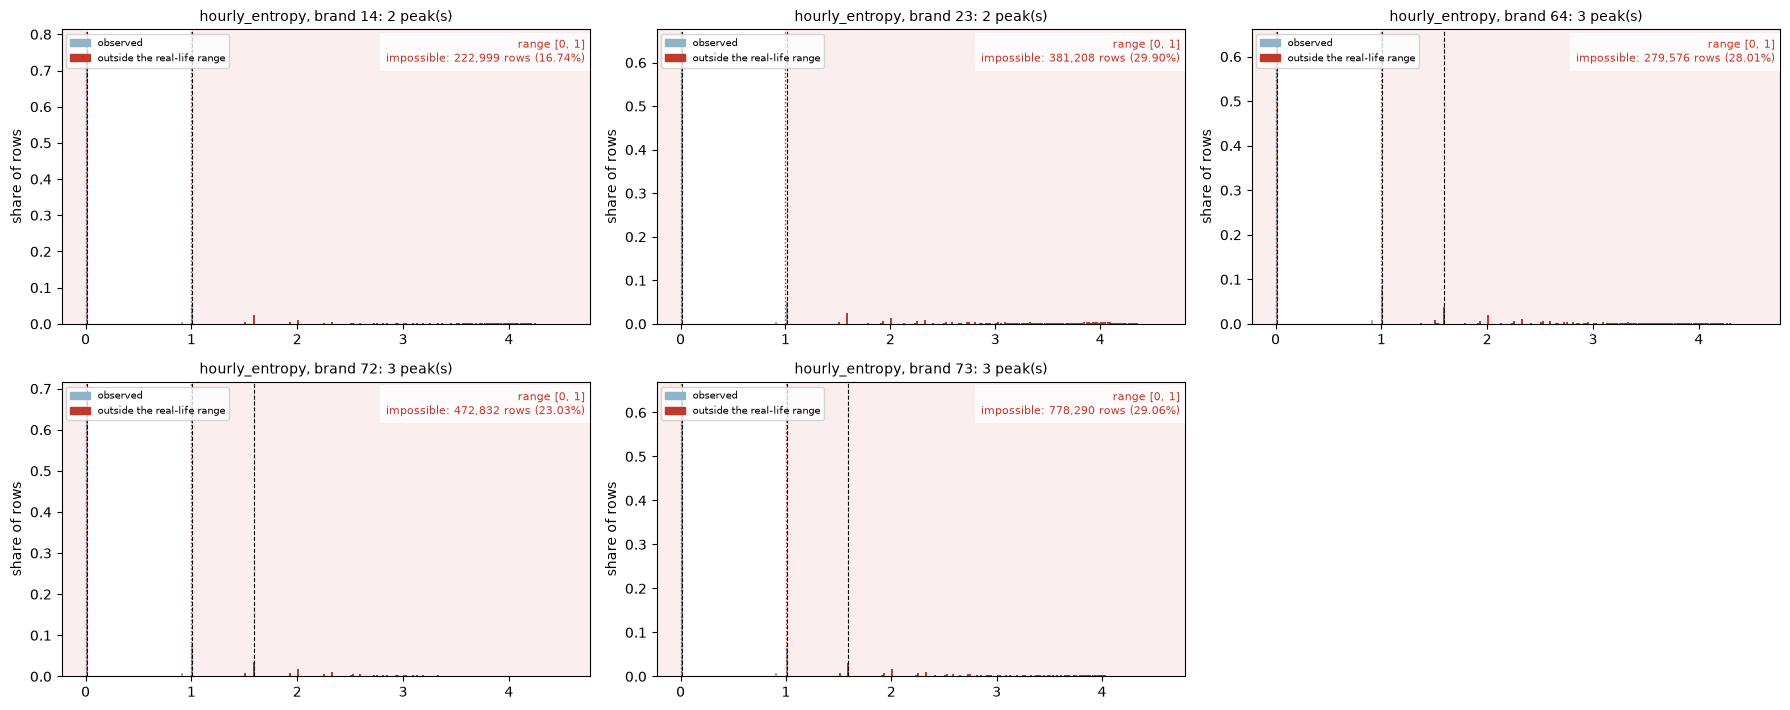

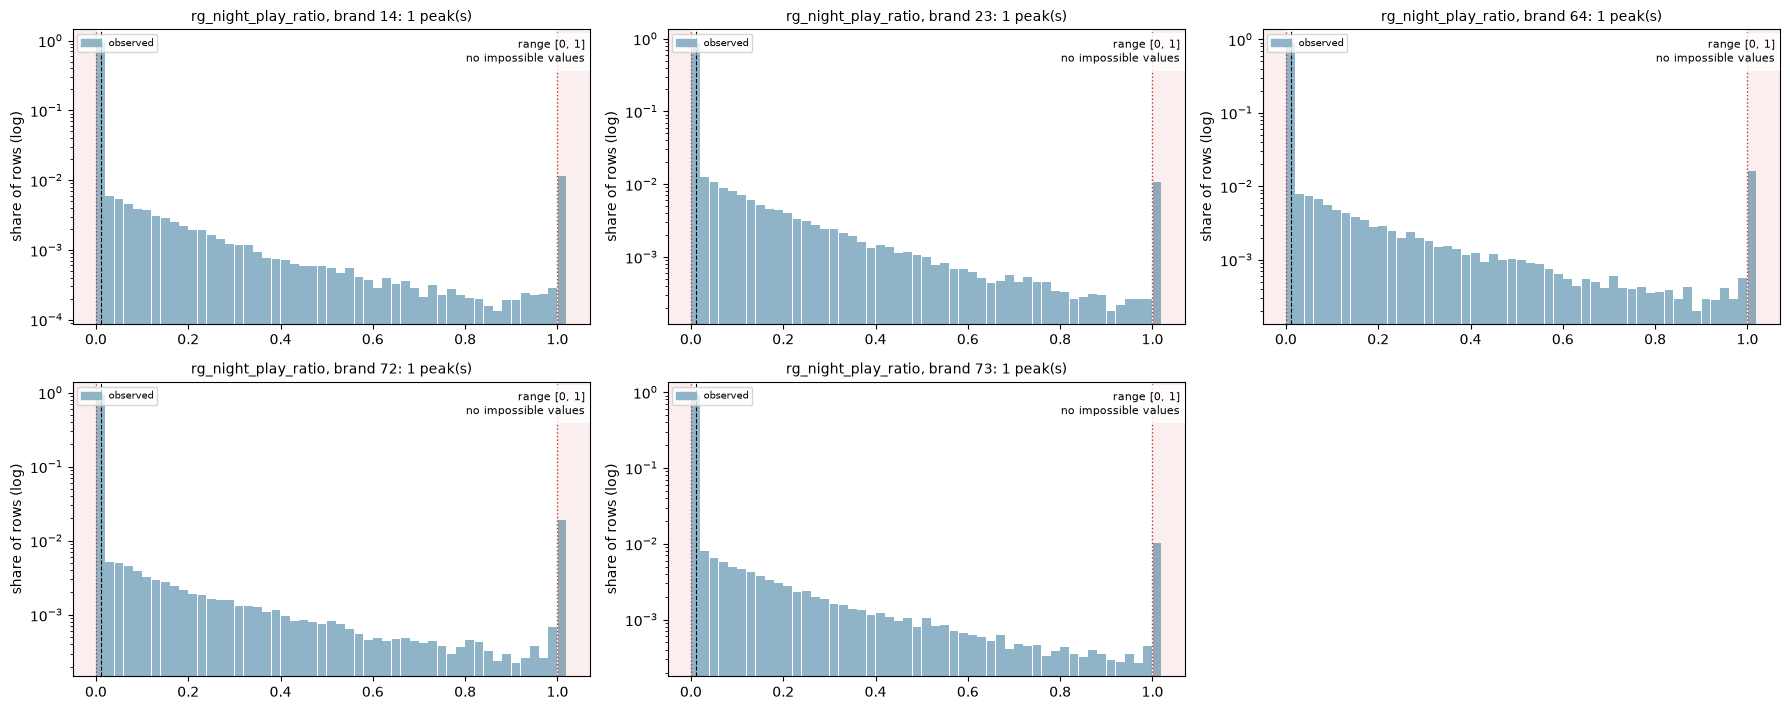

In [44]:
for name in METRICS:
    plots.brands(cfg, name)
    plt.show()

## 12. Every Suspicious Value

Each metric has two rules in `metrics.yaml`:

- **impossible:** cannot happen (a share above 1, a session over one day, a negative gap);
- **suspicious:** possible but rare, so it needs a check (over 1 M€ of turnover in a day, a session of exactly 1 second, over 50 deposits in a day…).

For each metric: how many values break each rule, on how many days, and in which brand. Only counts, never a player.

In [45]:
pd.DataFrame({n: {"impossible if": m.get("impossible", ""), "suspicious if": m.get("suspicious", ""), "note": m.get("note", "")}
              for n, m in cfg["metrics"].items()}).T

,impossible if,suspicious if,note
turnover_player_day,,x > 1000000,Turnover of one player in one day with play. Expected log-normal.
wagered_eur_l30d,,x > 10000000,"30-day stake from the signals table, on the players who staked."
avg_bet_eur_l30d,,x > 10000,Mean stake per bet. Very small or very large values point to unit or currenc...
deposit_size_eur,,x > 100000,"Mean deposit of a player in a day. Round amounts (10, 20, 50) can make small..."
sessions_per_active_day,,x > 20,Visits (sessions) of a player in a day with a visit. Expected Poisson; zero ...
active_days_l30d,x > 30,,"Days with play in the last 30 days. Bounded by 30, so a Poisson can only be ..."
bets_per_active_day,,x > 20000,"Bets in a day with play. Large counts, so it is shown on a log scale."
deposits_per_day,,x > 50,Deposits in a day with a deposit.
session_duration_avg_secs,x > 86400,x = 1 OR (x > 14400 AND x <= 86400),Mean session length of the player. A normal session lasts 30 minutes to 2 ho...
session_gap_avg_hours,x < 0,x > 0 AND x < 0.5,Mean hours between two sessions.


In [46]:
flags = pd.concat([audit.flags_by_day(cfg, t, **(LONG if t == "gld_player_signals_daily" else {}))
                   for t in dict.fromkeys(m["table"] for m in cfg["metrics"].values())], ignore_index=True)
register = audit.flags_summary(flags, cfg)
display(register.round(3))

,metric,impossible if,suspicious if,rows,impossible,impossible %,days with impossible,suspicious,suspicious %,days with suspicious,brand 14: susp. %,brand 23: susp. %,brand 64: susp. %,brand 72: susp. %,brand 73: susp. %
0,active_days_l30d,x > 30,,12678683,0,0.000,0,0,0.000,0,0.000,0.000,0.000,0.000,0.000
1,avg_bet_eur_l30d,,x > 10000,12412200,0,0.000,0,25,0.000,22,0.000,0.000,0.000,0.000,0.000
2,bets_per_active_day,,x > 20000,545380,0,0.000,0,111,0.020,30,0.015,0.033,0.004,0.020,0.014
3,deposit_size_eur,,x > 100000,395220,0,0.000,0,9,0.002,9,0.000,0.000,0.000,0.000,0.008
4,deposits_per_day,,x > 50,398831,0,0.000,0,43,0.011,25,0.003,0.001,0.000,0.018,0.028
5,hold_pct_l30d,x > 100,x < -1000,12412200,232,0.002,62,2469,0.020,137,0.003,0.012,0.013,0.017,0.039
6,hourly_entropy,x > 1,,25888187,7189973,27.773,102,0,0.000,0,0.000,0.000,0.000,0.000,0.000
7,median_session_duration_secs,x > 86400,x = 1 OR (x > 14400 AND x <= 86400),15535340,116508,0.750,92,957103,6.161,102,3.356,3.127,5.880,8.054,8.290
8,night_index,x > 1,,25888187,2094223,8.089,102,0,0.000,0,0.000,0.000,0.000,0.000,0.000
9,session_duration_avg_secs,x > 86400,x = 1 OR (x > 14400 AND x <= 86400),15535340,165342,1.064,98,1360735,8.759,102,5.465,6.898,6.228,7.504,13.796


**When:** share of suspicious values per day and brand (white = 0%, grey = no data).

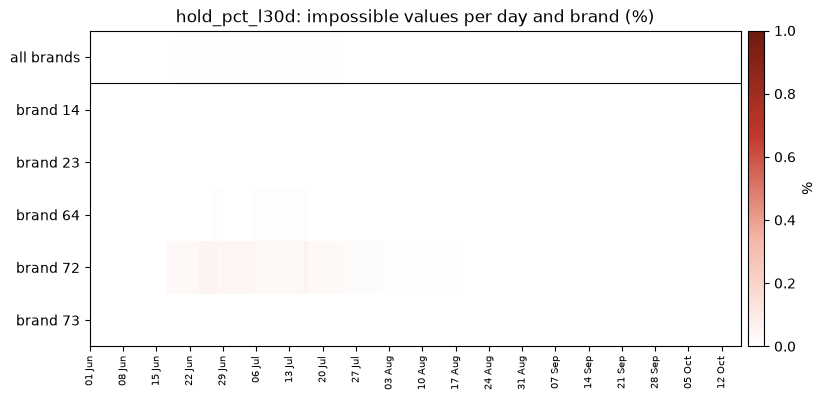

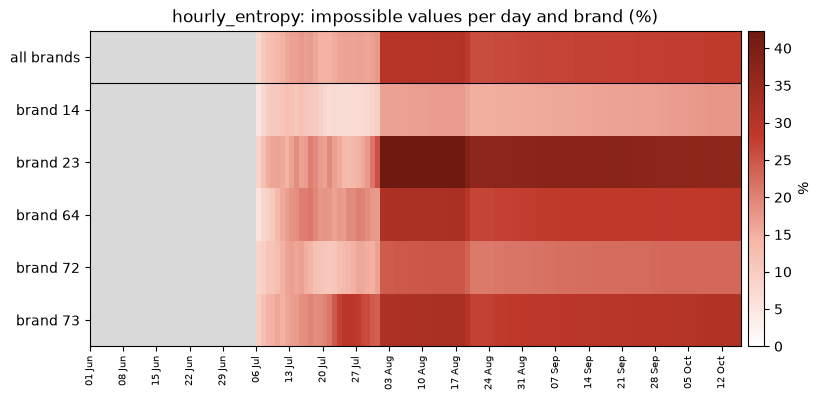

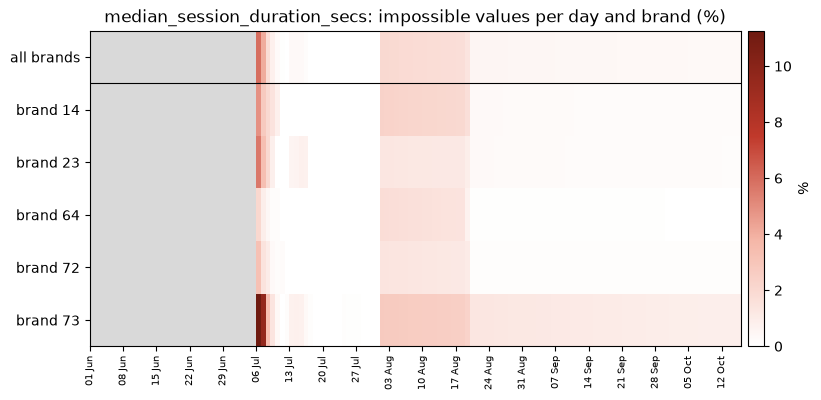

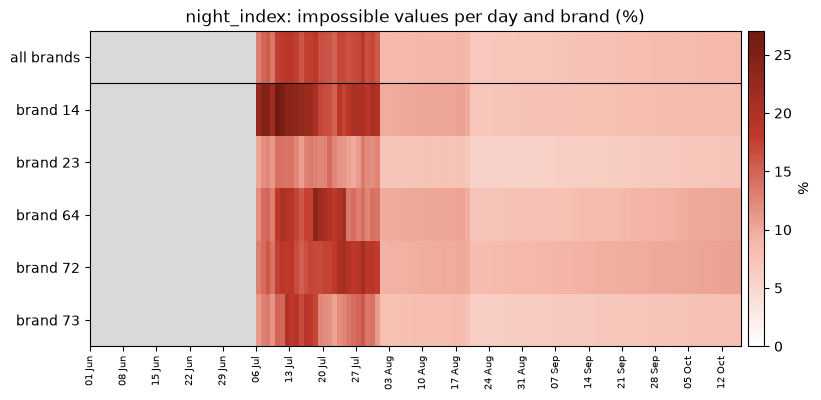

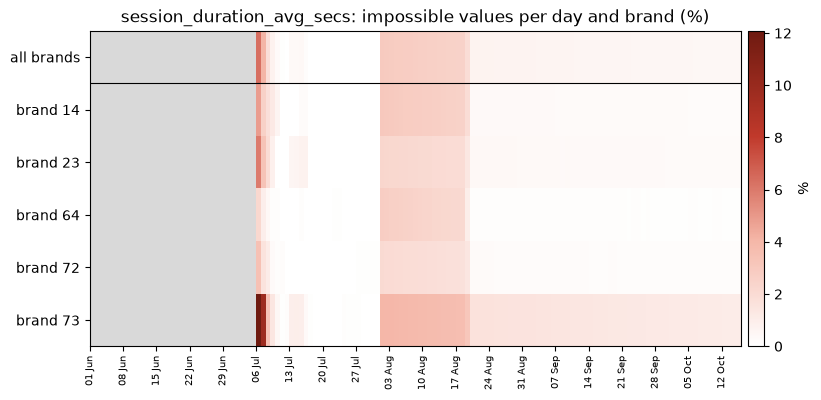

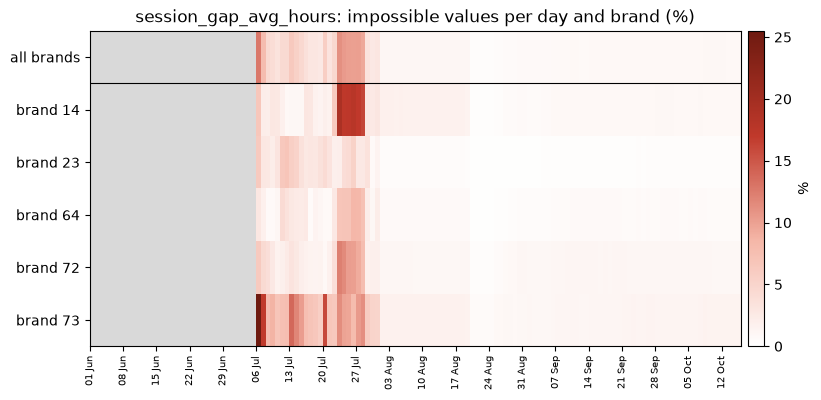

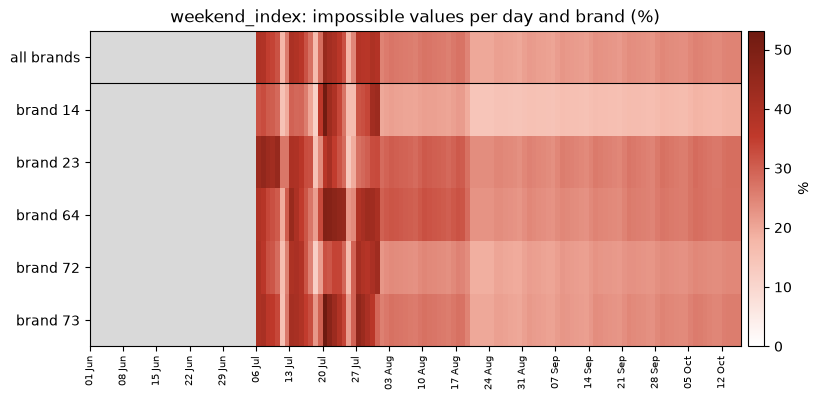

In [47]:
for name in register.loc[register["impossible"] > 0, "metric"]:
    plots.by_day(flags, name)
    plt.show()

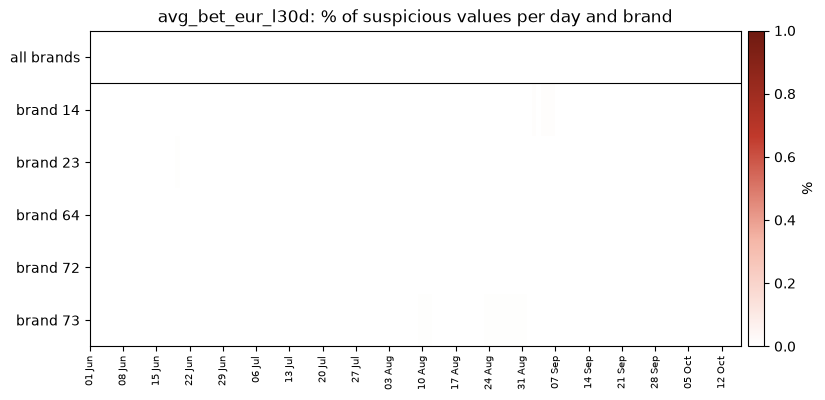

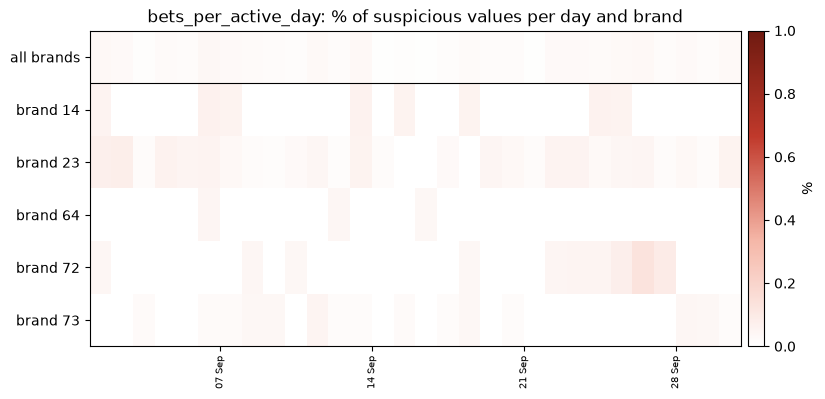

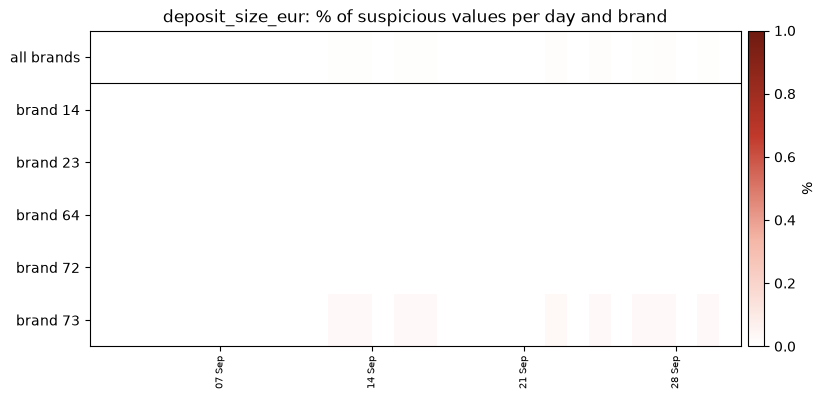

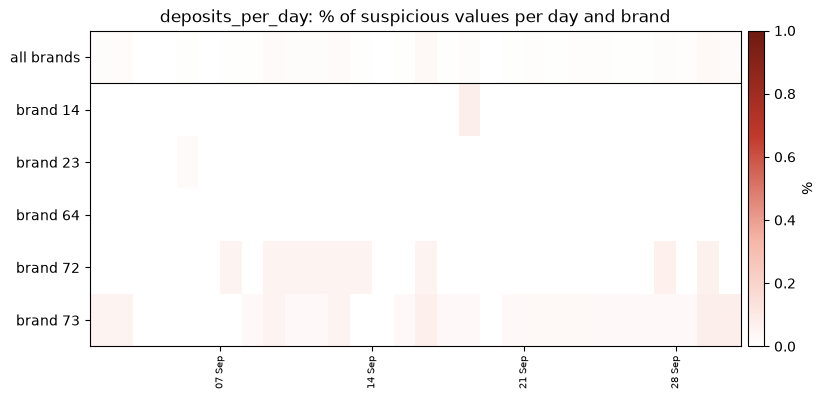

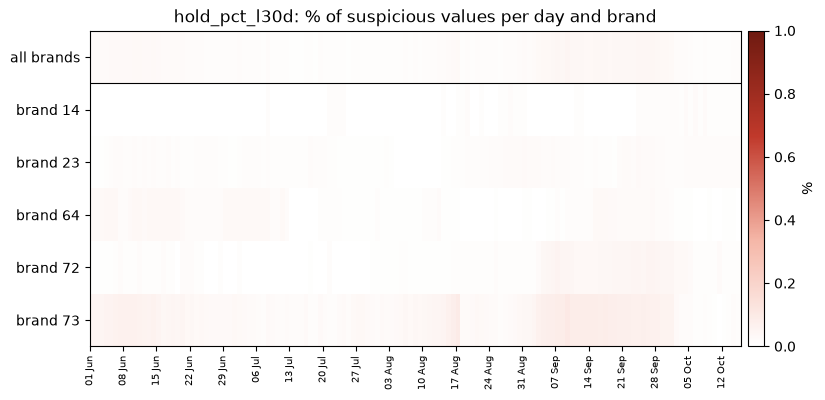

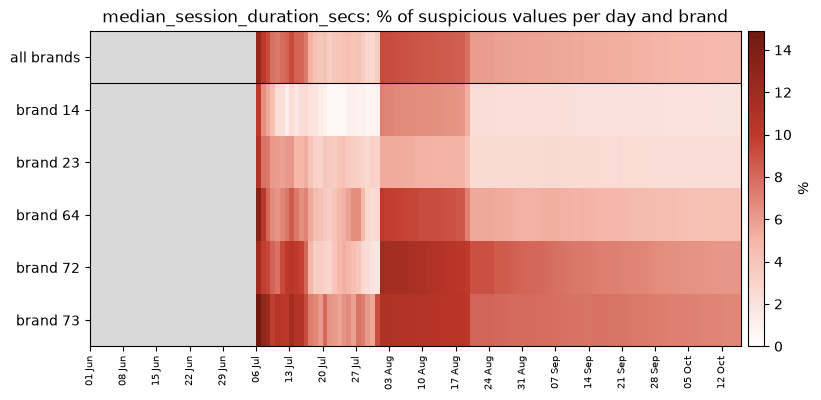

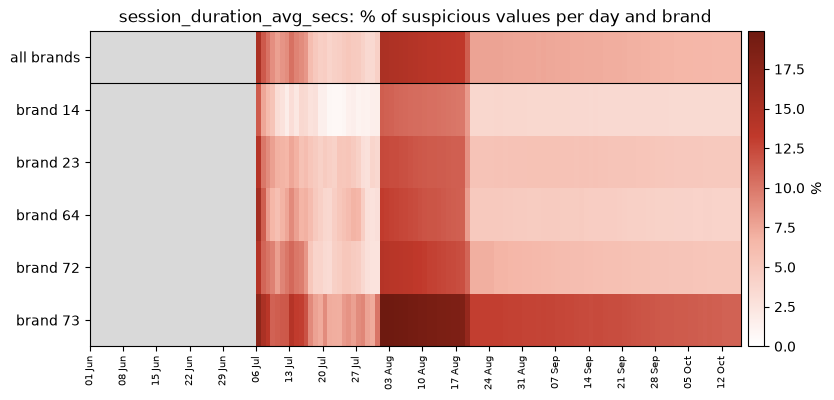

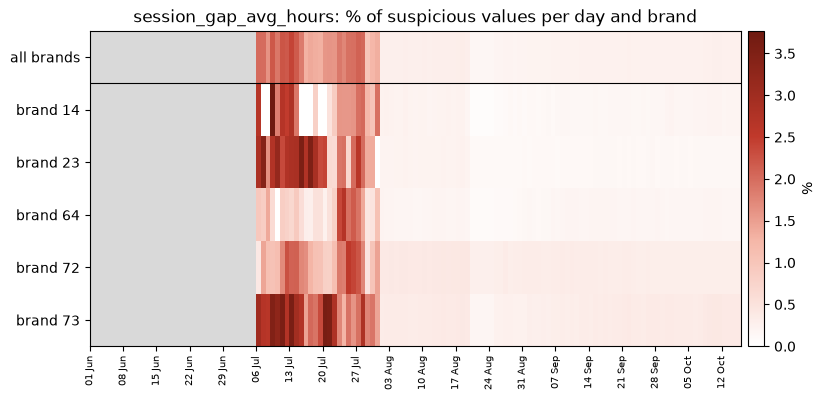

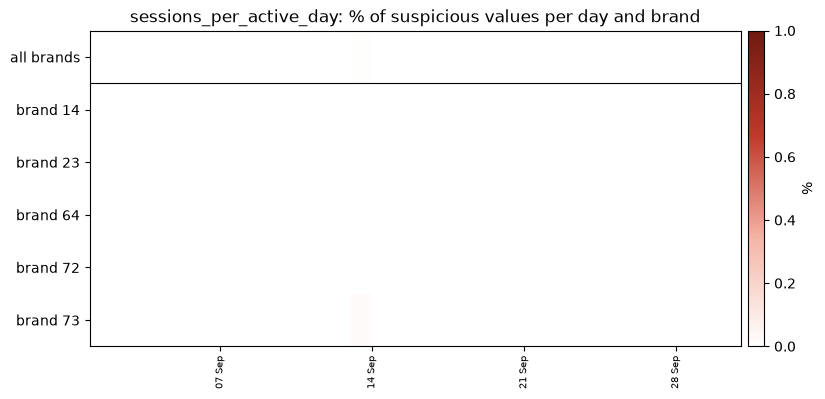

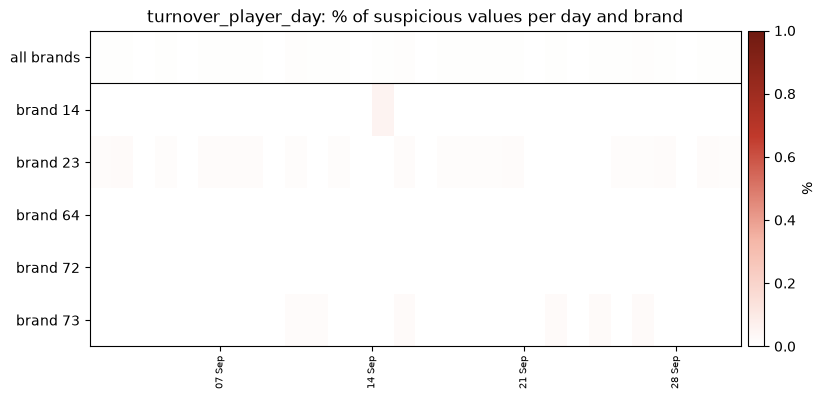

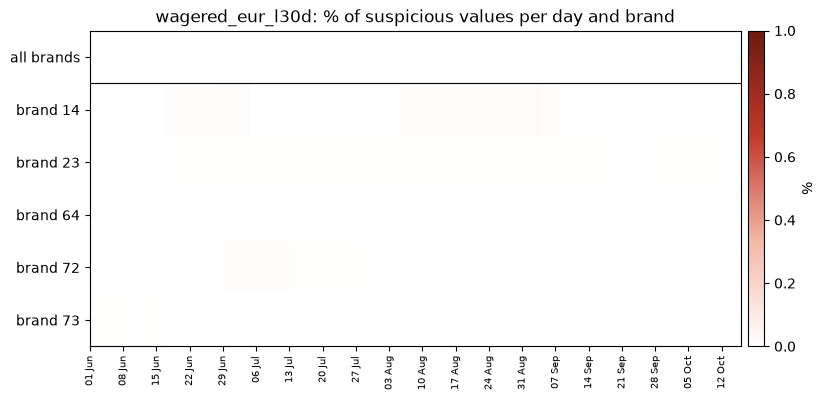

In [48]:
susp = flags.rename(columns={"impossible": "imp", "suspicious": "impossible"})   # the heatmap draws the `impossible` column
for name in register.loc[register["suspicious"] > 0, "metric"]:
    plots.by_day(susp, name, title=f"{name}: % of suspicious values per day and brand")
    plt.show()

**Which values:** the most frequent flagged values. A value that repeats a lot (exactly 1 second, exactly 4) points to a rule of the computation.

In [49]:
for name in register.loc[(register["impossible"] + register["suspicious"]) > 0, "metric"]:
    print(name)
    display(audit.flagged_values(cfg, name))

avg_bet_eur_l30d


,value,kind,brand,currency,rows,first_day,last_day
0,10232.3488,suspicious,73,EUR,5,2026-09-01,2026-09-05
1,23130.1277,suspicious,23,TRY,1,2026-09-22,2026-09-22
2,13315.0296,suspicious,23,TRY,1,2026-09-24,2026-09-24
3,10513.6454,suspicious,23,TRY,1,2026-09-23,2026-09-23


bets_per_active_day


,value,kind,brand,currency,rows,first_day,last_day
0,38335.0,suspicious,73,TRY,1,2026-09-15,2026-09-15
1,37167.0,suspicious,72,TRY,1,2026-09-22,2026-09-22
2,35668.0,suspicious,23,TRY,1,2026-09-06,2026-09-06
3,34254.0,suspicious,23,TRY,1,2026-09-30,2026-09-30
4,32302.0,suspicious,72,EUR,1,2026-09-25,2026-09-25
5,31644.0,suspicious,72,TRY,1,2026-09-27,2026-09-27
6,31332.0,suspicious,73,TRY,1,2026-09-06,2026-09-06
7,31294.0,suspicious,72,TRY,1,2026-09-24,2026-09-24
8,31151.0,suspicious,23,TRY,1,2026-09-10,2026-09-10
9,30762.0,suspicious,72,TRY,1,2026-09-26,2026-09-26


deposit_size_eur


...

,value,kind,brand,currency,rows,first_day,last_day
0,5.780959e+06,suspicious,14,TRY,1,2026-09-14,2026-09-14
1,4.597722e+06,suspicious,23,TRY,1,2026-09-02,2026-09-02
2,2.995832e+06,suspicious,23,TRY,1,2026-09-29,2026-09-29
3,2.947951e+06,suspicious,23,TRY,1,2026-09-26,2026-09-26
4,2.819648e+06,suspicious,23,TRY,1,2026-09-25,2026-09-25
5,2.800113e+06,suspicious,23,TRY,1,2026-09-10,2026-09-10
6,2.591602e+06,suspicious,23,TRY,1,2026-09-07,2026-09-07
7,2.536590e+06,suspicious,23,TRY,1,2026-09-27,2026-09-27
8,2.497929e+06,suspicious,23,TRY,1,2026-09-08,2026-09-08
9,2.467903e+06,suspicious,23,TRY,1,2026-09-20,2026-09-20


wagered_eur_l30d


,value,kind,brand,currency,rows,first_day,last_day
0,1.250757e+07,suspicious,73,EUR,2,2026-09-24,2026-09-25
1,5.469760e+07,suspicious,23,TRY,1,2026-09-04,2026-09-04
2,5.425956e+07,suspicious,23,TRY,1,2026-09-08,2026-09-08
3,5.409116e+07,suspicious,23,TRY,1,2026-09-12,2026-09-12
4,5.387199e+07,suspicious,23,TRY,1,2026-09-06,2026-09-06
5,5.335477e+07,suspicious,23,TRY,1,2026-09-07,2026-09-07
6,5.322763e+07,suspicious,23,TRY,1,2026-09-02,2026-09-02
7,5.317570e+07,suspicious,23,TRY,1,2026-09-03,2026-09-03
8,5.308015e+07,suspicious,23,TRY,1,2026-09-10,2026-09-10
9,5.278944e+07,suspicious,23,TRY,1,2026-09-13,2026-09-13


weekend_index


,value,kind,brand,currency,rows,first_day,last_day
0,3.5000,impossible,72,<NA>,215498,2026-09-01,2026-09-30
1,3.5000,impossible,73,<NA>,206569,2026-09-01,2026-09-30
2,3.5000,impossible,14,<NA>,109343,2026-09-01,2026-09-30
3,3.5000,impossible,64,<NA>,105341,2026-09-01,2026-09-30
4,3.5000,impossible,23,<NA>,91775,2026-09-01,2026-09-30
5,1.7500,impossible,73,<NA>,79967,2026-09-01,2026-09-30
6,1.7500,impossible,72,<NA>,59053,2026-09-01,2026-09-30
7,1.1667,impossible,73,<NA>,57349,2026-09-01,2026-09-30
8,1.1667,impossible,72,<NA>,38459,2026-09-01,2026-09-30
9,1.7500,impossible,64,<NA>,33008,2026-09-01,2026-09-30


## 13. Metrics With Index Limits

Scores (0 to 100), shares and entropy (0 to 1), hold (at most 100%) and other columns with fixed limits. For each brand: values outside the limits, and values **exactly at a limit**. A big mass at a limit means the value is cut, or it is the default for missing data.

In [50]:
limits, limit_hist = ev.index_limits(cfg)
allb = limits[limits["brand"] == "all"].drop(columns="brand").set_index("column")
display(allb.round(3))

,limits,note,rows,nulls,min,max,p1,median,p99,below %,above %,at lower limit %,at upper limit %,zero %
column,,,,,,,,,,,,,,
churn_score,"[0, 100]","score, workbook unit 0-1",17729256,0,0.000,1.000000e+02,0.000,50.000,100.000,0.0,0.000,2.842,5.766,2.842
recency_pressure,"[0, 100]","recency_score, workbook unit 0-1",17729256,0,0.000,1.000000e+02,0.000,100.000,100.000,0.0,0.000,3.079,91.800,3.079
frequency_decline,"[0, 100]","frequency_score, workbook unit 0-1",17729256,0,0.000,1.000000e+02,0.000,0.000,100.000,0.0,0.000,92.130,6.388,92.130
value_decline,"[0, 100]","monetary_score, workbook unit 0-1; the formula has no upper clamp",17729256,0,0.000,5.726838e+07,0.000,0.000,100.000,0.0,0.840,81.743,16.197,81.743
engagement_score,"[0, 100]","score, workbook unit 0-1",17729256,0,0.000,1.000000e+02,0.000,0.000,63.333,0.0,0.000,87.492,0.055,87.492
risk_score,"[0, 100]","rg_risk_score, workbook unit 0-1",17729256,0,0.000,9.195400e+01,0.000,0.000,26.270,0.0,0.000,92.763,0.000,92.763
risk_appetite_score,"[0, 100]","score, workbook unit 0-1",17729256,0,47.130,1.000000e+02,47.161,48.297,78.191,0.0,0.000,0.000,0.636,0.000
betting_aggression_score,"[0, 100]","score, workbook unit 0-1",17729256,0,23.569,1.000000e+02,24.289,49.075,66.936,0.0,0.000,0.000,0.126,0.000
session_intensity_score,"[0, 100]","min(100, ...)",17729256,0,0.000,1.000000e+02,0.000,0.000,84.574,0.0,0.000,97.856,0.656,97.856


In [51]:
broken = allb[(allb["below %"] > 0) | (allb["above %"] > 0)].index
print("outside their limits:", list(broken))
display(limits[limits["column"].isin(broken)].pivot_table(index="column", columns="brand", values=["below %", "above %"]).round(3))

outside their limits: ['value_decline', 'tp_night_index', 'tp_weekend_index', 'tp_hourly_entropy']


above %                                        below %                         
brand                  14      23      64     72      73     all      14   23   64   72   73  all
column                                                                                           
tp_hourly_entropy   8.830  18.320  12.063  9.963  12.844  12.042     0.0  0.0  0.0  0.0  0.0  0.0
tp_night_index      4.287   3.727   3.900  4.084   2.998   3.676     0.0  0.0  0.0  0.0  0.0  0.0
tp_weekend_index    8.665  13.756  10.804  9.644   9.903  10.227     0.0  0.0  0.0  0.0  0.0  0.0
value_decline       0.524   1.814   0.831  0.561   0.859   0.840     0.0  0.0  0.0  0.0  0.0  0.0

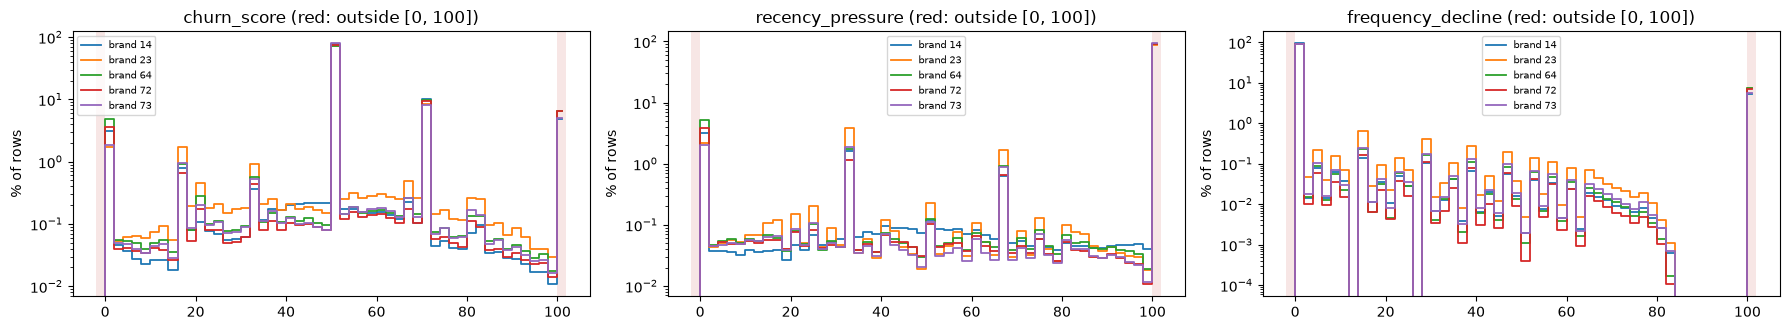

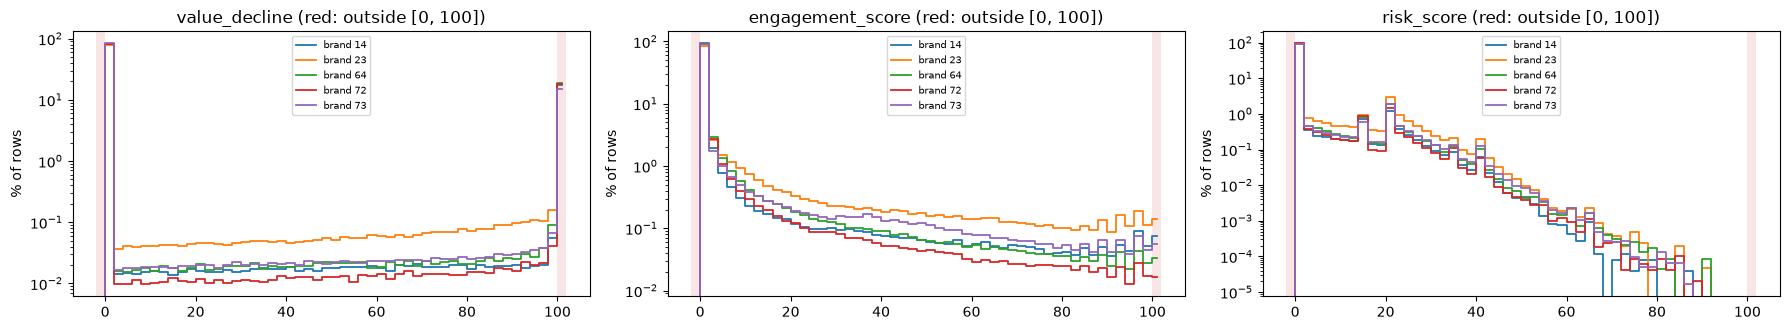

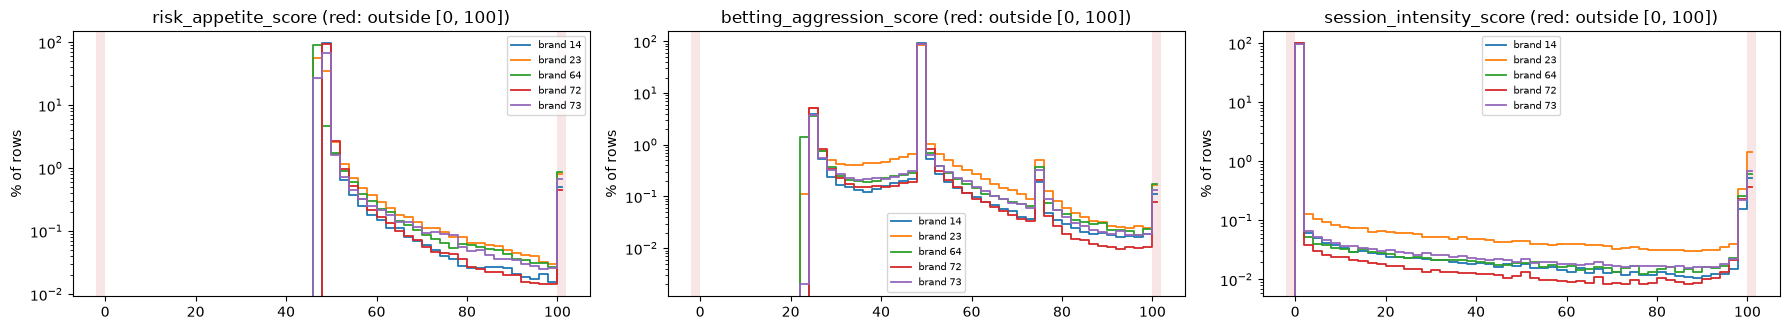

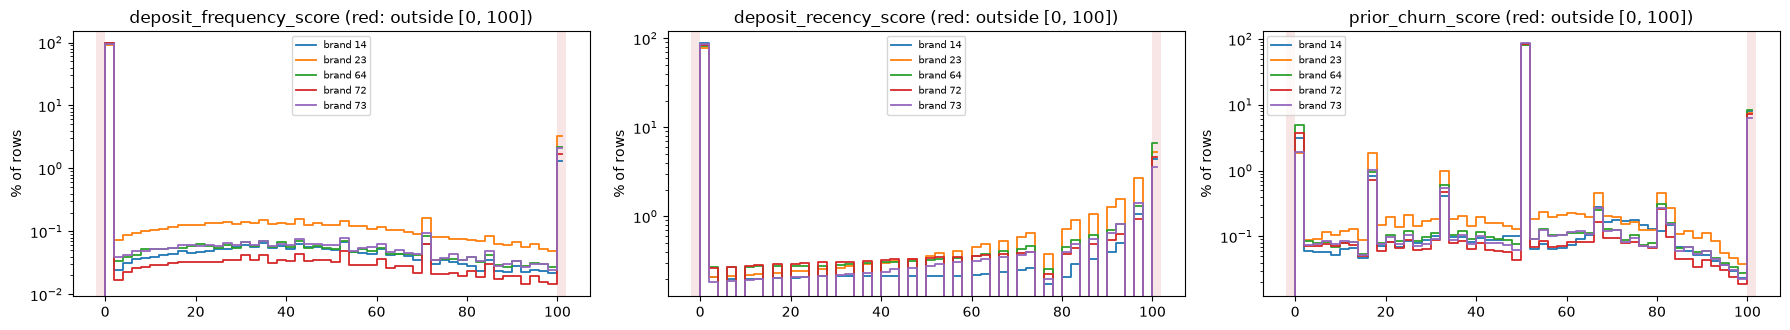

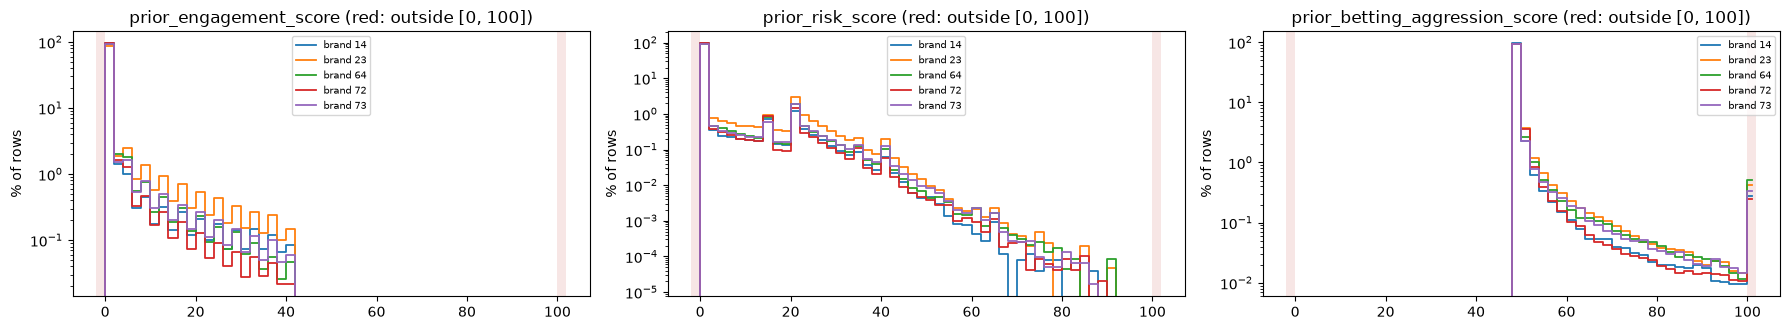

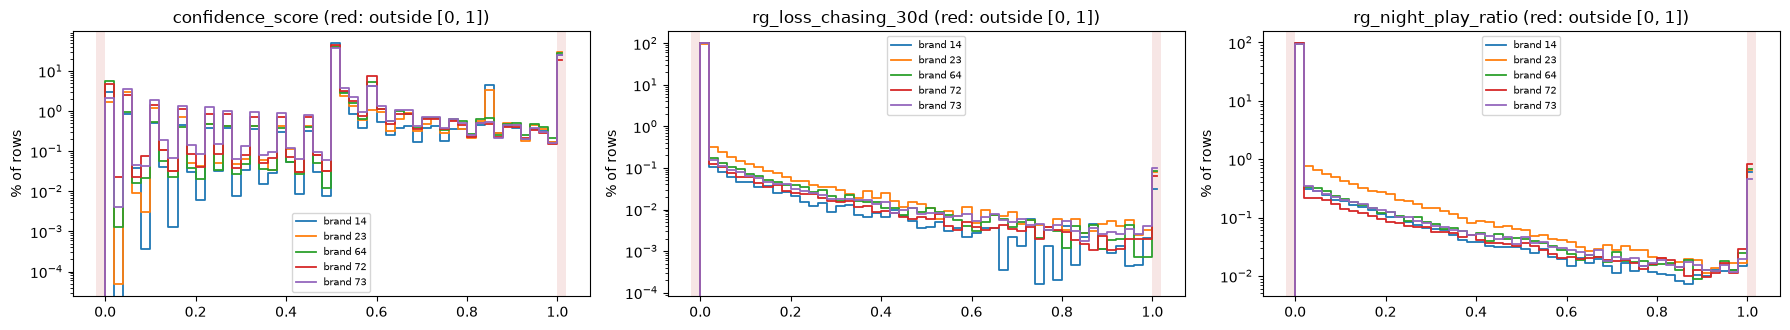

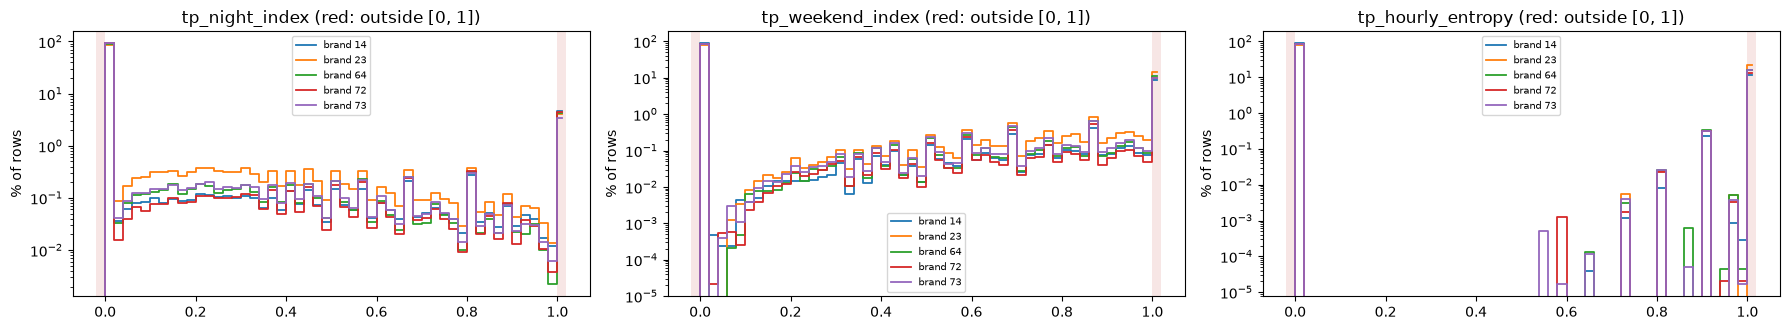

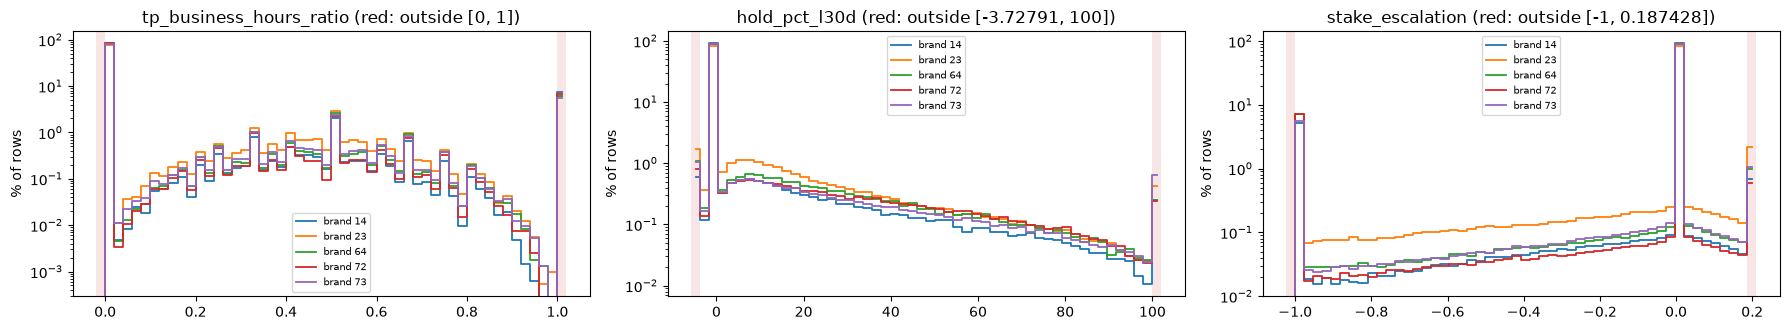

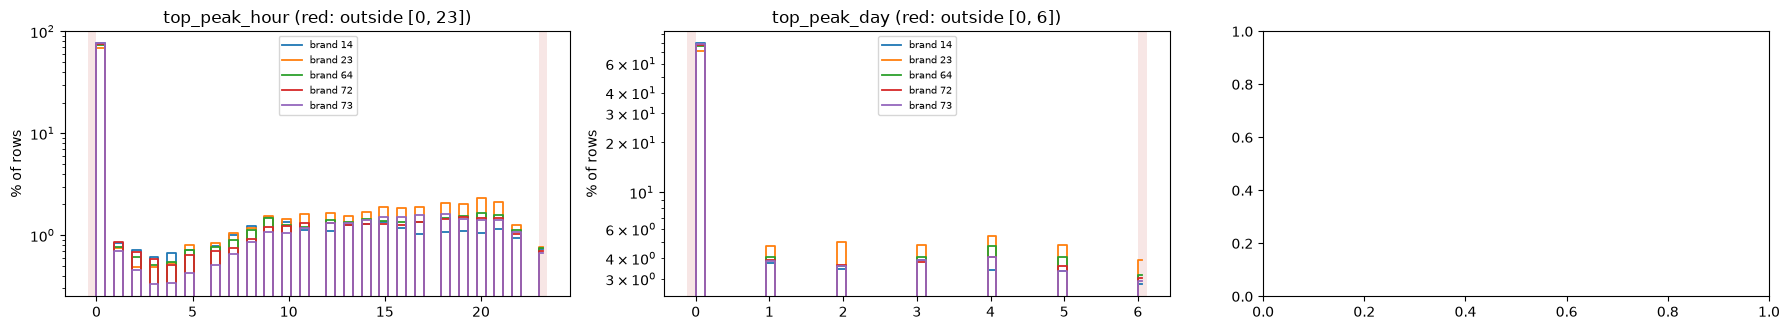

In [52]:
cols = list(ev.INDEX_LIMITS)
for k in range(0, len(cols), 3):
    fig, axes = plt.subplots(1, 3, figsize=(18, 3.4))
    for ax, c in zip(axes, cols[k:k + 3]):
        if c in set(limit_hist["column"]):
            plots.index_limits(limit_hist, c, ax)
        else:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

## 14. The Three Peaks of `hold_pct_l30d`

`hold_pct_l30d` = GGR / stake in 30 days, in %. 100% = the player lost everything; -100% = the player won twice the stake.

**The peak at -100% is not in the data.** The plot shown in the presentation stops at -100%, so all bigger wins fall in its first bar. Left: the plot as shown. Right: the same data without that edge (no S3).

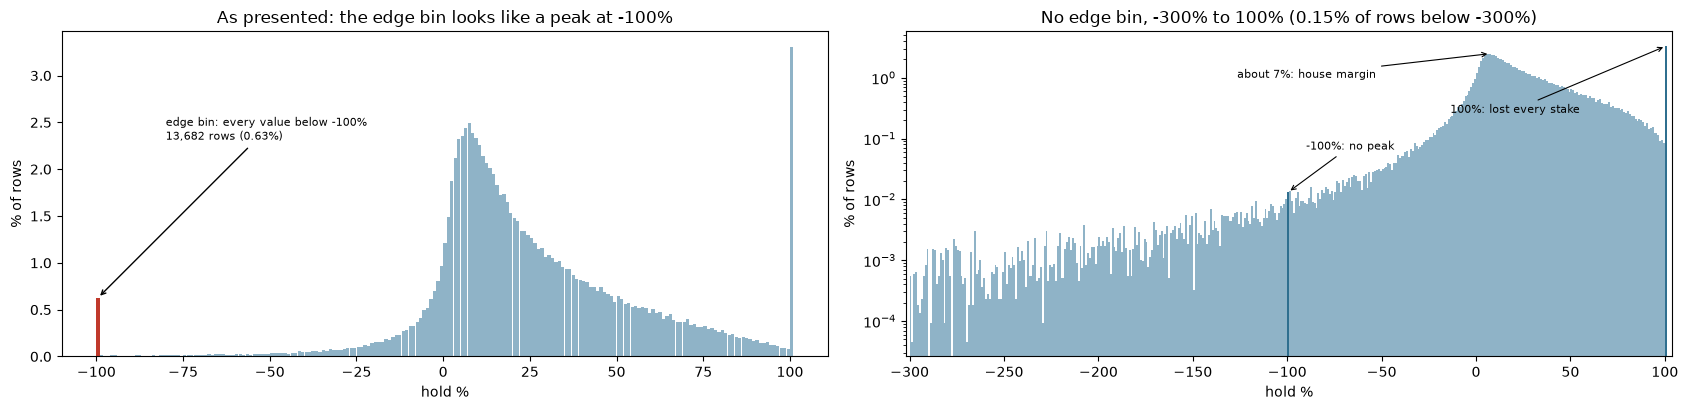

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
plots.hold_edge(cfg, axes)
plt.tight_layout()
plt.show()

**The middle peak and the peak at 100% are real.** The middle one (about 7%) is the house margin. The one at 100% is players who won nothing in 30 days, mostly players with very few bets.

,brand,rows,below -100,-101 to -99,exactly -100,0 to 20,exactly 100,won nothing
bets_30d,,,,,,,,
1 bet,all,27255,845.0,87.0,87.0,64.0,24269.0,24269.0
2 to 5,all,62614,1544.0,103.0,76.0,2624.0,33355.0,33355.0
21 to 100,all,350181,2203.0,39.0,0.0,48052.0,2747.0,2747.0
6 to 20,all,121927,1796.0,69.0,1.0,10860.0,11609.0,11609.0
all,all,2179191,13395.0,511.0,164.0,869677.0,72068.0,72068.0
over 100,all,1617214,7007.0,213.0,0.0,808077.0,88.0,88.0


,bets_30d,rows,below -100,-101 to -99,exactly -100,0 to 20,exactly 100,won nothing
brand,,,,,,,,
14,all,239031,783.0,46.0,1.0,105888.0,6398.0,6398.0
23,all,385413,1698.0,79.0,2.0,178229.0,8979.0,8979.0
64,all,305245,1952.0,58.0,10.0,120677.0,5758.0,5758.0
72,all,558349,3010.0,88.0,9.0,204429.0,11649.0,11649.0
73,all,691153,5952.0,240.0,142.0,260454.0,39284.0,39284.0
all,all,2179191,13395.0,511.0,164.0,869677.0,72068.0,72068.0


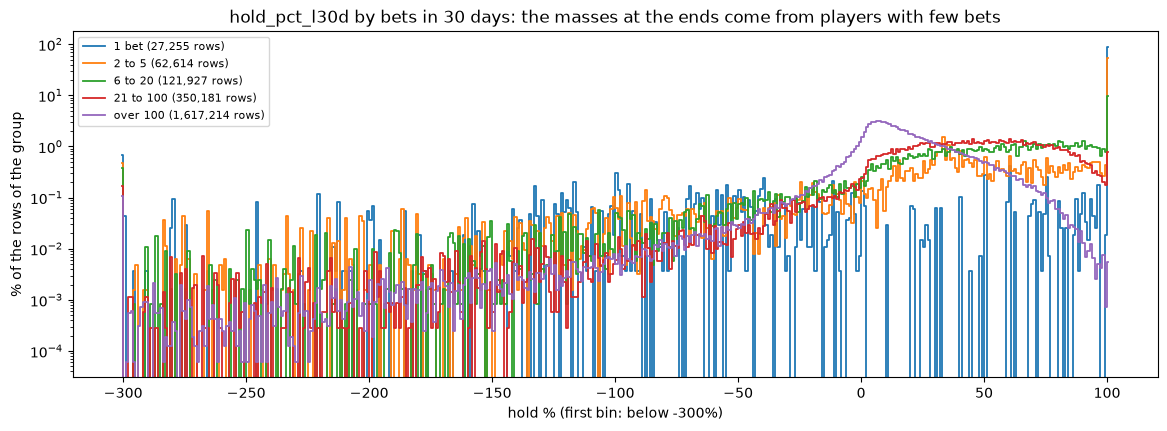

In [54]:
masses = ev.hold_masses(cfg)
display(masses[masses["brand"] == "all"].set_index("bets_30d").round(0))
display(masses[masses["bets_30d"] == "all"].set_index("brand").round(0))
fig, ax = plt.subplots(figsize=(14, 4.5))
plots.hold_by_bets(ev.hold_hist(cfg), ax)
plt.show()

## 15. Findings

September 2026, brands 14, 23, 64, 72 and 73, unless said otherwise.

### Shapes, peaks and missing data

- **Money is log-normal** (KS 0.03) and **counts are negative binomial** (KS 0.01 or less): each player plays at their own pace.
- **Two peaks only when there is a reason:** withdrawals have one payment flow per currency (EUR about 7 min, TRY about 36 min), and hold has a mass at 100%.
- **Missing data:** only `brand_id` has nulls (100% until July 2026, about 31% from 1 August). Other columns write 0 instead of null.
- **Impossible values:** session length (up to 28 days) and `tp_night_index` (up to 4), since 6 July 2026.

### By brand

- **The shapes are the same in every brand.**
- **The levels are not:** the median stake in 30 days goes from 89 € (brand 72) to 511 € (brand 23). One threshold for all brands does not fit each brand.
- **Two peaks that only show by brand:** deposit size in brands 14 and 23 (about 19 € and 38 €, probably round amounts in lira) and withdrawal time in brands 73 and 14.
- **Session length is worst in brand 73:** 14.1% outside 10 s to 4 h, against 4% to 7% in the others. Sessions of exactly 1 second are mostly in brand 72.

### Suspicious values

Columns of the signals table: 1 June to 15 October 2026. Other metrics: September.

| Metric | Impossible | Suspicious | Where |
|---|---|---|---|
| `tp_avg_session_duration_secs` | 1.1% (over 1 day) | 8.8% (1 s or 4 to 24 h) | Worst in brand 73 |
| `tp_median_session_duration_secs` | 0.75% | 6.2% | Worst in brands 72 and 73 |
| `tp_avg_session_gap_hours` | **0.86% negative** | 0.25% under 30 min | Every day |
| `hold_pct_l30d` | 232 rows over 100% (June to August) | 2,469 rows below -1000% | Mostly brands 72 and 73 |
| Deposits per day | | 43 over 50, up to 180 | Brands 72 and 73 only |
| Mean deposit | | 9 over 100,000 € | Brand 73 only |
| Bets per day | | 111 over 20,000 | Mostly TRY: bots or autoplay |

- The same value often repeats over many days: a few players whose value does not change while the window moves.
- The most frequent flagged values are listed in section 12, ready for the data team.

### Metrics with index limits

- **Outside the limits:** `tp_hourly_entropy`, `tp_weekend_index`, `tp_night_index`, and **`value_decline` (up to 57 million)**, which has no upper limit and feeds `churn_score`.
- **Stuck at a limit:** `recency_pressure` is 100 in **92%** of the rows, so it hardly separates players.
- **Default = valid value:** `top_peak_hour` and `top_peak_day` are 0 in about 75% of the rows, but 0 is also a real hour and day.
- **Units:** the workbook says 0-1 for every score; production uses 0 to 100.

### The three peaks of `hold_pct_l30d`

- **-100%:** not in the data, it is the edge of the plot.
- **About 7%:** real, the house margin.
- **100%:** real, players who won nothing; 80% of them have 5 bets or fewer.
- **For the model:** hold with few bets is noise. Use it only above a minimum number of bets.